# NOVA B10 · Preference tuning with DPO

Extends the chat model of B04 with Direct Preference Optimization (Rafailov et al., 2023). Starting from the MoE chat checkpoint, the model is trained on pairs of a preferred and a rejected answer to the same prompt (Intel/orca_dpo_pairs), with the chat checkpoint itself as the frozen reference. No reward model is trained: the loss directly raises the probability of the preferred answer relative to the rejected one, while β keeps the model close to the reference.

| Measure (500 held-out pairs) | Before DPO | After DPO |
|---|---|---|
| Model prefers the chosen answer (average log-probability per token) | 32.8% | **65.0%** |
| Implicit reward accuracy | - | 98.8% |
| smol-smoltalk validation loss | 1.908 | 1.983 |
| Probe tokens moved to a different expert pair | - | 6-8% (chat tuning: 26-30%) |

**Finding:** the model learns the preference, but largely through answer length (chosen answers average 115 tokens, rejected 193), so its answers become much shorter and sometimes degenerate, and the chat validation loss rises. DPO moves far fewer tokens to other experts than chat tuning did.

## Hardware
Confirms the GPU and the PyTorch build used for this notebook.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch; print('torch', torch.__version__, '| cuda available:', torch.cuda.is_available())

name, memory.total [MiB]
NVIDIA GeForce RTX 5050 Laptop GPU, 8151 MiB
torch 2.11.0+cu128 | cuda available: True


## Model, training and analysis code
Same files as B02-B07: model, data utilities, routing analysis, chat fine-tuning helpers and the chat interface.

In [2]:
%%writefile model.py
"""
Team NOVA - AFML Project
model.py: our own decoder-only transformer, with an optional Mixture-of-Experts FFN.

Differences from the video (GPT-2 style) model, and why:
  * RMSNorm instead of LayerNorm  - no mean-centering, fewer ops, equally stable (LLaMA)
  * RoPE instead of learned position embeddings - relative positions via rotating Q and K
  * SwiGLU feed-forward instead of GELU MLP     - gated FFN, lower loss at equal params
  * No bias terms                                - fewer params, no quality loss at this scale
  * Weight tying (kept from GPT-2)               - input embedding = output projection
  * MoE switch: any layer listed in config.moe_layers uses MoEFFN instead of SwiGLU.
    With moe_layers = () the model is a plain dense transformer (Phase 1).
  * Optional (used by the Base model on C4, off for the small model):
      - Grouped-query attention (n_kv_head < n_head): several query heads share one key/value head
        (LLaMA-2 70B, LLaMA-3, Mistral). Fewer parameters and a 3x smaller KV cache, same quality.
      - QK-norm (qk_norm=True): RMSNorm on each query and key head before RoPE (OLMo-2, Qwen3,
        Gemma-3). Keeps attention logits bounded, which matters in float16 on a T4.

Shapes: B = batch, T = sequence length, C = n_embd, H = n_head, D = head size, V = vocab.
"""

import math
from dataclasses import dataclass, field

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class ModelConfig:
    vocab_size: int = 8192
    block_size: int = 256          # max context length T
    n_layer: int = 6
    n_head: int = 6                # query heads H
    n_kv_head: int = 0             # key/value heads; 0 means = n_head (ordinary multi-head attention)
    qk_norm: bool = False          # RMSNorm on q and k per head
    n_embd: int = 384              # C
    ffn_hidden: int = 1024         # SwiGLU hidden size (~ 8/3 * C, rounded)
    dropout: float = 0.0           # each training token is seen about once, so no dropout
    rope_theta: float = 10000.0
    # --- Mixture of Experts (Phase 2). Empty tuple = dense model. ---
    moe_layers: tuple = ()         # e.g. (1, 3, 5) = MoE in alternate layers
    n_experts: int = 8
    top_k: int = 2
    expert_hidden: int = 512       # each expert is half the dense FFN width


# ----------------------------------------------------------------------------
# Building blocks
# ----------------------------------------------------------------------------
class RMSNorm(nn.Module):
    """y = x / sqrt(mean(x^2) + eps) * g.  Like LayerNorm but without subtracting the mean."""

    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        # compute in float32 for stability under mixed precision
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return xf.type_as(x) * self.weight


def build_rope_cache(T, D, theta, device):
    """Precompute cos/sin for rotary embeddings. Returns two (T, D/2) tensors."""
    inv_freq = 1.0 / (theta ** (torch.arange(0, D, 2, device=device).float() / D))  # (D/2,)
    t = torch.arange(T, device=device).float()                                       # (T,)
    freqs = torch.outer(t, inv_freq)                                                 # (T, D/2)
    return freqs.cos(), freqs.sin()


def apply_rope(x, cos, sin):
    """Rotate each pair (x1, x2) of features by an angle that depends on the position.

    x: (B, H, T, D). Pairing: first half of D with second half.
    After rotation, q·k depends only on the RELATIVE distance between positions.
    """
    D = x.shape[-1]
    x1, x2 = x[..., : D // 2], x[..., D // 2 :]
    cos, sin = cos[None, None], sin[None, None]          # (1, 1, T, D/2)
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)


class CausalSelfAttention(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head = cfg.n_head
        self.n_kv_head = cfg.n_kv_head or cfg.n_head                    # Hkv
        assert self.n_head % self.n_kv_head == 0, "query heads must split evenly into KV groups"
        self.head_dim = cfg.n_embd // cfg.n_head                        # D
        self.kv_dim = self.n_kv_head * self.head_dim                    # Hkv * D (= C without GQA)
        self.qkv = nn.Linear(cfg.n_embd, cfg.n_embd + 2 * self.kv_dim, bias=False)  # C -> C + 2*Hkv*D
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)      # C -> C
        if cfg.qk_norm:
            self.q_norm, self.k_norm = RMSNorm(self.head_dim), RMSNorm(self.head_dim)
        else:
            self.q_norm = self.k_norm = None
        self.dropout = cfg.dropout

    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split([C, self.kv_dim, self.kv_dim], dim=2)  # (B,T,C), 2 x (B,T,Hkv*D)
        # (B, T, C) -> (B, H, T, D); keys and values have Hkv heads
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        if self.q_norm is not None:                                     # QK-norm, before RoPE
            q, k = self.q_norm(q), self.k_norm(k)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        if self.n_kv_head != self.n_head:                               # GQA: each KV head serves
            rep = self.n_head // self.n_kv_head                         # n_head / n_kv_head query heads
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        # softmax(q k^T / sqrt(D) + causal mask) v, computed by a fused kernel
        y = F.scaled_dot_product_attention(
            q, k, v, is_causal=True, dropout_p=self.dropout if self.training else 0.0
        )                                                               # (B, H, T, D)
        y = y.transpose(1, 2).contiguous().view(B, T, C)                # (B, T, C)
        return self.proj(y)


class SwiGLU(nn.Module):
    """FFN(x) = W_down( SiLU(W_gate x) * (W_up x) ).  Applied to each token independently."""

    def __init__(self, n_embd, hidden):
        super().__init__()
        self.gate = nn.Linear(n_embd, hidden, bias=False)
        self.up = nn.Linear(n_embd, hidden, bias=False)
        self.down = nn.Linear(hidden, n_embd, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))


class MoEFFN(nn.Module):
    """Top-k Mixture of Experts feed-forward layer (Phase 2).

    router:  logits z = W_r h            (one score per expert, per token)
    select:  the top_k experts by z
    combine: y = sum_{i in top-k} g_i * Expert_i(h),  g = softmax over the top-k logits

    Also returns:
      aux_loss  - Switch-Transformer load-balancing loss  E * sum_i f_i * P_i
      z_loss    - mean(logsumexp(z)^2), keeps router logits small and stable
      routing   - dict with logits / chosen experts, used by the research analysis
    """

    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.n_experts = cfg.n_experts
        self.top_k = cfg.top_k
        self.router = nn.Linear(cfg.n_embd, cfg.n_experts, bias=False)
        self.experts = nn.ModuleList(
            [SwiGLU(cfg.n_embd, cfg.expert_hidden) for _ in range(cfg.n_experts)]
        )
        # Research hook (Phase 6, counterfactual routing). Not a parameter, never saved.
        # Set to (mask, idx): mask (N,) bool marks tokens to override, idx (N, k) their forced experts.
        self.force_route = None

    def forward(self, x, valid=None):
        """valid: optional (B, T) bool mask; padding tokens (False) are left out of the balancing
        statistics (aux loss, z-loss). They are still routed, which does not affect real tokens
        because causal attention never lets a real token see the padding after it."""
        B, T, C = x.shape
        h = x.reshape(-1, C)                                            # (N, C), N = B*T
        logits = self.router(h).float()                                 # (N, E)
        probs = logits.softmax(dim=-1)                                  # (N, E)
        top_logits, top_idx = logits.topk(self.top_k, dim=-1)           # (N, k)
        if self.force_route is not None:                                # counterfactual: force experts
            mask, forced = self.force_route
            top_idx = torch.where(mask[:, None], forced, top_idx)
            top_logits = logits.gather(1, top_idx)                      # gates from the forced experts
        gates = top_logits.softmax(dim=-1).type_as(h)                   # (N, k), renormalized

        out = torch.zeros_like(h)
        for e in range(self.n_experts):
            token_pos, slot = (top_idx == e).nonzero(as_tuple=True)     # tokens routed to e
            if token_pos.numel() == 0:
                continue
            y = self.experts[e](h[token_pos])                           # (n_e, C)
            out.index_add_(0, token_pos, y * gates[token_pos, slot, None])

        # load balancing: f_i = fraction of routing slots sent to expert i,
        #                 P_i = mean router probability of expert i
        v = torch.ones(h.shape[0], device=h.device) if valid is None else valid.reshape(-1).float()
        n_valid = v.sum().clamp(min=1.0)
        f = torch.zeros(self.n_experts, device=h.device)
        f.scatter_add_(0, top_idx.reshape(-1), v.repeat_interleave(self.top_k))
        f = f / (n_valid * self.top_k)
        P = (probs * v[:, None]).sum(dim=0) / n_valid
        aux_loss = self.n_experts * (f * P).sum()
        z_loss = (torch.logsumexp(logits, dim=-1).pow(2) * v).sum() / n_valid

        routing = {"logits": logits.detach(), "top_idx": top_idx.detach()}
        return out.view(B, T, C), aux_loss, z_loss, routing


class Block(nn.Module):
    """Pre-norm transformer block:  x = x + attn(norm(x));  x = x + ffn(norm(x))."""

    def __init__(self, cfg: ModelConfig, layer_idx: int):
        super().__init__()
        self.norm1 = RMSNorm(cfg.n_embd)
        self.attn = CausalSelfAttention(cfg)
        self.norm2 = RMSNorm(cfg.n_embd)
        self.is_moe = layer_idx in cfg.moe_layers
        self.ffn = MoEFFN(cfg) if self.is_moe else SwiGLU(cfg.n_embd, cfg.ffn_hidden)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, cos, sin, valid=None):
        x = x + self.drop(self.attn(self.norm1(x), cos, sin))
        if self.is_moe:
            y, aux, z, routing = self.ffn(self.norm2(x), valid)
            return x + self.drop(y), aux, z, routing
        return x + self.drop(self.ffn(self.norm2(x))), None, None, None


# ----------------------------------------------------------------------------
# The full model
# ----------------------------------------------------------------------------
class NovaLM(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.blocks = nn.ModuleList([Block(cfg, i) for i in range(cfg.n_layer)])
        self.norm_f = RMSNorm(cfg.n_embd)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight                      # weight tying

        cos, sin = build_rope_cache(cfg.block_size, cfg.n_embd // cfg.n_head, cfg.rope_theta, "cpu")
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        self.apply(self._init_weights)
        # scale down the layers that write into the residual stream (GPT-2 trick):
        # each block adds 2 contributions, so std / sqrt(2 * n_layer) keeps variance steady
        for name, p in self.named_parameters():
            if name.endswith("proj.weight") or name.endswith("down.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def num_params(self):
        """Total parameters (tied weights counted once)."""
        return sum(p.numel() for p in self.parameters())

    def num_active_params(self):
        """Parameters used per token (MoE: only top_k of n_experts experts)."""
        total = self.num_params()
        for b in self.blocks:
            if b.is_moe:
                per_expert = sum(p.numel() for p in b.ffn.experts[0].parameters())
                total -= (self.cfg.n_experts - self.cfg.top_k) * per_expert
        return total

    def forward(self, idx, targets=None, loss_mask=None, return_routing=False, valid_mask=None):
        """
        idx:       (B, T) token ids
        targets:   (B, T) next-token ids (idx shifted by one) -> teacher forcing
        loss_mask: (B, T) 1 where the loss counts, 0 elsewhere (instruction tuning, Phase 3)
        valid_mask: (B, T) True for real tokens, False for padding (MoE balancing statistics only)
        Returns logits (B, T, V), loss (or None), and an info dict.
        """
        B, T = idx.shape
        assert T <= self.cfg.block_size, f"sequence length {T} > block_size {self.cfg.block_size}"
        x = self.tok_emb(idx)                                           # (B, T, C)
        cos, sin = self.rope_cos[:T], self.rope_sin[:T]

        aux_losses, z_losses, routings = [], [], {}
        for i, block in enumerate(self.blocks):
            x, aux, z, routing = block(x, cos, sin, valid_mask)
            if aux is not None:
                aux_losses.append(aux)
                z_losses.append(z)
                if return_routing:
                    routings[i] = routing
        x = self.norm_f(x)
        logits = self.lm_head(x)                                        # (B, T, V)

        info = {
            "aux_loss": torch.stack(aux_losses).mean() if aux_losses else None,
            "z_loss": torch.stack(z_losses).mean() if z_losses else None,
            "routing": routings,
        }
        if targets is None:
            return logits, None, info

        per_token = F.cross_entropy(
            logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1), reduction="none"
        )
        if loss_mask is None:
            loss = per_token.mean()
        else:
            m = loss_mask.reshape(-1).float()
            loss = (per_token * m).sum() / m.sum().clamp(min=1.0)
        return logits, loss, info

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=50, eot_id=None):
        """Sample tokens one at a time. Stops early when every sequence has produced eot_id."""
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size :]
            logits, _, _ = self(idx_cond)
            logits = logits[:, -1, :].float() / max(temperature, 1e-5)
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float("inf")
            next_id = torch.multinomial(logits.softmax(-1), num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
            if eot_id is not None and (next_id == eot_id).all():
                break
        return idx

Overwriting model.py


In [3]:
%%writefile train.py
"""
Team NOVA - AFML Project
train.py: pretraining (dense or MoE) on the FineWeb-Edu/C4/Wikipedia mix (the earlier small model used TinyStories), with resumable checkpoints.

Fixes compared with the video training loop:
  * the loop counts OPTIMIZER steps; gradient accumulation happens inside each step
  * the LR schedule is computed per optimizer step: linear warmup -> cosine decay to min_lr
  * min_lr < lr (the video had min_lr = 5x lr, so its LR went UP)
  * backward() outside the autocast block; GradScaler only for float16
  * weight decay only on matrices (not on norm gains)
  * checkpoints + CSV log saved to Google Drive, and training resumes after a disconnect
  * periodic weight snapshots, kept for the training-dynamics analysis (Phase 7)
  * Drive-friendly: the resumable checkpoint is written every --resume_every_min minutes (old copies of overwritten
    files can sit in Drive's Bin and count against the quota), free space is checked before every save, and a full
    Drive gives a warning instead of a crash
  * one session per run folder (RUNNING heartbeat), and DONE.json when a run has finished

Example (Colab, T4 GPU):
    python train.py --data_dir /content/drive/MyDrive/nova/data \
                    --out_dir  /content/drive/MyDrive/nova/runs/dense --preset dense
"""

import argparse
import atexit
import csv
import json
import math
import os
import shutil
import socket
import time
import uuid
from contextlib import nullcontext
from dataclasses import asdict

import numpy as np
import torch

from model import ModelConfig, NovaLM

# "Base" model for the C4 corpus (course feedback: scale the SLM up), in the GPT-2-small size class:
# 12 blocks, width 768, 12 query heads sharing 4 key/value heads (grouped-query attention), QK-norm.
# Dense ~88M parameters. MoE: 8 experts of half width in blocks 3, 7, 11 (code indices 2, 6, 10),
# ~131M total / ~88M active per token. Exact counts are printed at the start of training and checked in tests.
BASE = dict(block_size=512, n_layer=12, n_head=12, n_kv_head=4, qk_norm=True,
            n_embd=768, ffn_hidden=2048, expert_hidden=1024)
# Fallback if the T4 is too slow for the Base model: the earlier 60M configuration (10 x 640, plain attention).
BASE60 = dict(block_size=512, n_layer=10, n_head=10, n_embd=640, ffn_hidden=1728, expert_hidden=864)

PRESETS = {
    # Phase 1: dense baseline
    "dense": dict(moe_layers=()),
    # Phase 2: MoE in alternate layers, 8 experts, top-2, with load balancing
    "moe": dict(moe_layers=(1, 3, 5)),
    # Phase 2 ablation: same MoE but trained WITHOUT the load-balancing loss
    "moe_nobal": dict(moe_layers=(1, 3, 5)),
    # Base models on C4 (same recipe as above, larger)
    "base_dense": dict(BASE, moe_layers=()),
    "base_moe": dict(BASE, moe_layers=(2, 6, 10)),
    "base_moe_nobal": dict(BASE, moe_layers=(2, 6, 10)),
    # Placement ablation (TA question): MoE in blocks 1, 2, 5 (code indices 0, 1, 4) instead of 3, 7, 11.
    # Same number of MoE layers, so exactly the same parameter count; only WHERE the experts sit changes.
    "base_moe_early": dict(BASE, moe_layers=(0, 1, 4)),
    "moe_early": dict(moe_layers=(0, 1, 4)),
    "base60_dense": dict(BASE60, moe_layers=()),
    "base60_moe": dict(BASE60, moe_layers=(2, 5, 8)),
    "base60_moe_nobal": dict(BASE60, moe_layers=(2, 5, 8)),
    # tiny config for a quick smoke test (runs on CPU in seconds)
    "tiny": dict(n_layer=2, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64, block_size=64),
    "tiny_moe": dict(n_layer=2, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64,
                     block_size=64, moe_layers=(1,), n_experts=4),
    "tiny_moe8": dict(n_layer=4, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64,
                      block_size=64, moe_layers=(1, 3), n_experts=8),
    # tiny stand-ins for the Base model's attention (grouped-query + QK-norm), used by the Base smoke tests
    "tiny_adv": dict(n_layer=2, n_head=4, n_kv_head=2, qk_norm=True, n_embd=64, ffn_hidden=128,
                     expert_hidden=64, block_size=64),
    "tiny_moe8_adv": dict(n_layer=4, n_head=4, n_kv_head=2, qk_norm=True, n_embd=64, ffn_hidden=128,
                          expert_hidden=64, block_size=64, moe_layers=(1, 3), n_experts=8),
}


# Training defaults per preset (anything passed on the command line still wins). The three Base runs
# share one recipe so that dense vs MoE vs no-balancing stay a fair comparison:
# 8 x 16 x 512 = 65,536 tokens per step x 6,000 steps = 393M tokens. Micro-batch 8 keeps the 88M model
# well inside the T4's 15 GB; the effective batch is 8 x 16 = 128 sequences, the same as before.
PRESET_TRAIN = {
    name: dict(batch_size=8, grad_accum=16, max_steps=6000, lr=6e-4, min_lr=6e-5, snapshot_interval=1500)
    for name in ("base_dense", "base_moe", "base_moe_nobal", "base_moe_early",
                 "base60_dense", "base60_moe", "base60_moe_nobal")
}


def uses_balancing(preset):
    """The *_nobal presets are the ablation: same MoE, trained WITHOUT the load-balancing loss."""
    return not preset.endswith("nobal")


def get_args():
    p = argparse.ArgumentParser()
    p.add_argument("--data_dir", required=True)
    p.add_argument("--out_dir", required=True)
    p.add_argument("--preset", default="dense", choices=list(PRESETS))
    p.add_argument("--max_steps", type=int, default=10000, help="optimizer steps")
    p.add_argument("--batch_size", type=int, default=32, help="sequences per micro-batch")
    p.add_argument("--grad_accum", type=int, default=4, help="micro-batches per optimizer step")
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--min_lr", type=float, default=1e-4)
    p.add_argument("--warmup_steps", type=int, default=300)
    p.add_argument("--weight_decay", type=float, default=0.1)
    p.add_argument("--grad_clip", type=float, default=1.0)
    p.add_argument("--aux_coef", type=float, default=0.01, help="load-balancing loss weight")
    p.add_argument("--z_coef", type=float, default=1e-3, help="router z-loss weight")
    p.add_argument("--eval_interval", type=int, default=250)
    p.add_argument("--eval_iters", type=int, default=50)
    p.add_argument("--snapshot_interval", type=int, default=1000,
                   help="save weights-only snapshots for the training-dynamics analysis")
    p.add_argument("--resume_every_min", type=float, default=45,
                   help="write the resumable checkpoint (weights + optimizer) to out_dir at most this often")
    p.add_argument("--compact_optimizer", action="store_true",
                   help="store Adam's moments in bfloat16 in the resumable checkpoint (smaller files on Google Drive)")
    p.add_argument("--init_from", default="",
                   help="continue a run from a weight snapshot (snapshot_stepXXXXXX.pt): weights + step from the "
                        "snapshot, fresh optimizer state, log rows after that step removed (recovery after a broken run)")
    p.add_argument("--save_best", action="store_true",
                   help="also keep ckpt_best.pt (not used later: pretrained models are always taken at the last step)")
    p.add_argument("--seed", type=int, default=1337)
    p.add_argument("--no_resume", action="store_true")
    p.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    preset = p.parse_known_args()[0].preset
    p.set_defaults(**PRESET_TRAIN.get(preset, {}))
    return p.parse_args()


# ----------------------------------------------------------------------------
# Data
# ----------------------------------------------------------------------------
def val_dev_end(val_path, eot_id=0):
    """Index where the validation file is split in two (validation / test), at a document boundary.
    [0, dev_end)  = development half: research probe set, forgetting checks during fine-tuning
    [dev_end, :)  = TEST half: touched only by final_eval.py (notebook 06)."""
    data = np.memmap(val_path, dtype=np.uint16, mode="r")
    mid = len(data) // 2
    return mid + int(np.argmax(data[mid:] == eot_id)) + 1


class Batcher:
    """Random windows of block_size+1 tokens from a uint16 memmap: x = w[:-1], y = w[1:].
    limit: only sample windows that end before this token index (e.g. the development half)."""

    def __init__(self, path, block_size, batch_size, device, seed, limit=None):
        self.path, self.T, self.B, self.device = path, block_size, batch_size, device
        self.n = len(np.memmap(path, dtype=np.uint16, mode="r"))
        if limit is not None:
            self.n = min(self.n, int(limit))
        self.rng = np.random.default_rng(seed)

    def get(self):
        data = np.memmap(self.path, dtype=np.uint16, mode="r")   # re-open: avoids memmap RAM growth
        ix = self.rng.integers(0, self.n - self.T - 1, size=self.B)
        w = np.stack([data[i : i + self.T + 1] for i in ix]).astype(np.int64)
        w = torch.from_numpy(w)
        x, y = w[:, :-1].contiguous(), w[:, 1:].contiguous()
        if self.device.startswith("cuda"):
            return (x.pin_memory().to(self.device, non_blocking=True),
                    y.pin_memory().to(self.device, non_blocking=True))
        return x.to(self.device), y.to(self.device)


def lr_at(step, args):
    """Linear warmup to lr, then cosine decay to min_lr at max_steps."""
    if step < args.warmup_steps:
        return args.lr * (step + 1) / args.warmup_steps
    progress = (step - args.warmup_steps) / max(1, args.max_steps - args.warmup_steps)
    return args.min_lr + 0.5 * (args.lr - args.min_lr) * (1 + math.cos(math.pi * min(progress, 1.0)))


def make_optimizer(model, args):
    decay = [p for p in model.parameters() if p.requires_grad and p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.dim() < 2]
    groups = [{"params": decay, "weight_decay": args.weight_decay},
              {"params": no_decay, "weight_decay": 0.0}]
    fused = args.device.startswith("cuda")
    return torch.optim.AdamW(groups, lr=args.lr, betas=(0.9, 0.95), eps=1e-8, fused=fused)


@torch.no_grad()
def evaluate(model, batchers, eval_iters, ctx):
    model.eval()
    out = {}
    for split, b in batchers.items():
        b.rng = np.random.default_rng(999)       # same eval batches every time -> comparable numbers
        losses = []
        for _ in range(eval_iters):
            x, y = b.get()
            with ctx:
                _, loss, _ = model(x, y)
            losses.append(loss.item())
        out[split] = float(np.mean(losses))
    model.train()
    return out


def sample_text(model, tok, device, eot_id, prompt="Once upon a time", n_tokens=120):
    if tok is None:
        return ""
    idx = torch.tensor([tok.encode(prompt).ids], device=device)
    out = model.generate(idx, n_tokens, temperature=0.8, top_k=50, eot_id=eot_id)
    model.train()
    return tok.decode(out[0].tolist())


# ----------------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------------
LOCK_STALE_S = 600        # a RUNNING heartbeat older than 10 minutes belongs to a dead session


def read_lock(path):
    """(seconds since the last heartbeat, session id) of a RUNNING file, or (None, None).
    A heartbeat written on THIS machine by a process that no longer exists (e.g. after a kernel restart) counts as
    stale at once; one written on another machine counts as alive until it is LOCK_STALE_S old."""
    try:
        with open(path) as f:
            d = json.load(f)
        age = time.time() - float(d["t"])
    except Exception:
        return None, None
    if os.name != "nt" and d.get("host") == socket.gethostname() and d.get("pid"):   # (on Windows os.kill(pid, 0)
                                                                                     #  would send Ctrl+C, so skip)
        try:
            os.kill(int(d["pid"]), 0)          # signal 0: only checks that the process exists
        except ProcessLookupError:
            age = float("inf")
        except (PermissionError, OSError, ValueError):
            pass
    return age, d.get("id")


def write_json(path, obj):
    with open(path + ".tmp", "w") as f:
        json.dump(obj, f)
    os.replace(path + ".tmp", path)


# ---------------- saving to Google Drive without filling it ----------------
# Every overwrite of a file on Drive can leave the old copy in Drive's Bin, which counts against the 15 GB quota.
# So big files are written rarely: the resumable checkpoint every --resume_every_min minutes (not at every evaluation),
# with Adam's two moment estimates stored in bfloat16 (one third smaller), and every save checks the free space first.
def compact_optimizer_state(sd):
    """Copy of optimizer.state_dict() with floating-point state (Adam's moments) in bfloat16. The live optimizer is not
    touched. load_state_dict casts the values back to the parameters' float32; the rounding happens once per resume."""
    small = lambda k, v: v.to(torch.bfloat16) if torch.is_tensor(v) and v.is_floating_point() and k != "step" else v
    return {"state": {i: {k: small(k, v) for k, v in st.items()} for i, st in sd["state"].items()},
            "param_groups": sd["param_groups"]}


def nbytes(obj):
    if torch.is_tensor(obj):
        return obj.numel() * obj.element_size()
    if isinstance(obj, dict):
        return sum(nbytes(v) for v in obj.values())
    if isinstance(obj, (list, tuple)):
        return sum(nbytes(v) for v in obj)
    return 0


DRIVE_FULL = ("Google Drive may be full: open drive.google.com -> Bin -> Empty bin (and delete files you do not need). "
              "Training continues and tries again at the next evaluation.")


def safe_save(state, path):
    """Atomic save (write .tmp, then rename). Returns False (with a clear message) instead of crashing when there is
    not enough free space, so a full Drive never kills a training run."""
    try:
        free = shutil.disk_usage(os.path.dirname(os.path.abspath(path))).free
    except OSError:
        free = None
    need = 1.1 * nbytes(state) + 50e6
    if free is not None and free < need:
        print(f"WARNING: only {free / 1e9:.2f} GB free, {os.path.basename(path)} needs {need / 1e9:.2f} GB; not saved. "
              + DRIVE_FULL)
        return False
    try:
        with open(path + ".tmp", "wb") as f:
            torch.save(state, f)
            f.flush()
            os.fsync(f.fileno())          # on disk before the rename: a power cut cannot leave a half-written file
        os.replace(path + ".tmp", path)
        return True
    except (OSError, RuntimeError) as e:
        try:
            os.remove(path + ".tmp")
        except OSError:
            pass
        print(f"WARNING: could not save {os.path.basename(path)} ({type(e).__name__}: {str(e)[:120]}). " + DRIVE_FULL)
        return False


def save_until_done(state, path, tries=60):
    """The final weights must reach Drive: retry every minute (up to an hour) while the user frees space."""
    for i in range(tries):
        if safe_save(state, path):
            return True
        print(f"   retrying in 60 s ({i + 1}/{tries}); the trained model is still in memory, do not stop the cell")
        time.sleep(60)
    raise RuntimeError(f"could not save {path}")


def main():
    args = get_args()
    os.makedirs(args.out_dir, exist_ok=True)
    torch.manual_seed(args.seed)

    meta = json.load(open(os.path.join(args.data_dir, "meta.json")))
    eot_id = meta["special_tokens"]["<|endoftext|>"]
    try:
        from tokenizers import Tokenizer
        tok = Tokenizer.from_file(os.path.join(args.data_dir, "tokenizer.json"))
    except Exception:
        tok = None

    cfg = ModelConfig(vocab_size=meta["vocab_size"], **PRESETS[args.preset])
    use_aux = uses_balancing(args.preset)
    device = args.device
    model = NovaLM(cfg).to(device)
    optimizer = make_optimizer(model, args)

    # mixed precision: bfloat16 if the GPU supports it (A100/L4), else float16 + GradScaler (T4)
    if device.startswith("cuda"):
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        ctx = torch.autocast(device_type="cuda", dtype=dtype)
    else:
        dtype, ctx = torch.float32, nullcontext()
    scaler = torch.amp.GradScaler("cuda", enabled=(dtype == torch.float16))

    # ---------------- one session per run folder ----------------
    # Teammates share one Drive folder. Two Colab sessions training the same run would overwrite each other's
    # checkpoints, so a running session keeps a heartbeat in RUNNING (rewritten every 2 minutes) and a second
    # session refuses to start while that heartbeat is fresh (stale after 10 min, or at once if its process is gone).
    lock_path = os.path.join(args.out_dir, "RUNNING")
    done_path = os.path.join(args.out_dir, "DONE.json")
    session = uuid.uuid4().hex
    if not args.no_resume:
        age, owner = read_lock(lock_path)
        if age is not None and age < LOCK_STALE_S and owner != session:
            print(f"Another session is training {args.out_dir} right now (heartbeat {age / 60:.1f} min ago); "
                  f"not starting a second copy. If that session is dead, run this again in "
                  f"{(LOCK_STALE_S - age) / 60:.0f} min, or delete {lock_path}.")
            return

    # ---------------- resume ----------------
    ckpt_path = os.path.join(args.out_dir, "ckpt_last.pt")
    step, best_val = 0, float("inf")
    rewarm_from = None                    # set when continuing from a snapshot (fresh Adam moments need a short warmup)
    def all_finite(sd):
        return all(torch.isfinite(v).all().item() for v in sd.values() if torch.is_tensor(v) and v.is_floating_point())

    log_path = os.path.join(args.out_dir, "log.csv")
    if args.init_from:
        # recovery: weights + step from a snapshot, fresh optimizer; the LR schedule continues from that step
        ck = torch.load(args.init_from, map_location=device, weights_only=False)
        if not all_finite(ck["model"]):
            raise SystemExit(f"{args.init_from} contains NaN/inf weights; choose an earlier snapshot.")
        model.load_state_dict({k: (v.float() if v.is_floating_point() else v) for k, v in ck["model"].items()})
        step = int(ck["step"])
        if os.path.exists(log_path):                      # keep only the log rows up to the snapshot
            rows = list(csv.reader(open(log_path)))
            keep = [rows[0]] + [r for r in rows[1:] if r and int(r[0]) <= step]
            with open(log_path, "w", newline="") as f:
                csv.writer(f).writerows(keep)
            vals = [float(r[4]) for r in keep[1:] if math.isfinite(float(r[4]))]
            best_val = min(vals) if vals else float("inf")
        for f in (ckpt_path, done_path):
            if os.path.exists(f):
                os.remove(f)
        rewarm_from = step
        print(f"Continuing from snapshot step {step} ({args.init_from}) with a fresh optimizer state "
              f"(learning rate re-warmed over 100 steps)")
    elif os.path.exists(ckpt_path) and not args.no_resume:
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        if not all_finite(ck["model"]):
            raise SystemExit(f"{ckpt_path} contains NaN/inf weights (broken run). Continue from the last good "
                             f"snapshot instead: add --init_from {args.out_dir}/snapshot_stepXXXXXX.pt")
        if "optimizer" not in ck:                         # finished runs keep weights only (saves Drive space)
            print(f"Run already finished at step {ck['step']} (best val {ck['best_val']:.4f}); nothing to do.")
            if not os.path.exists(done_path):
                write_json(done_path, {"step": ck["step"], "best_val": ck["best_val"]})
            return
        model.load_state_dict(ck["model"])
        optimizer.load_state_dict(ck["optimizer"])
        # Make sure Adam's moments are float32 like the weights. (Older checkpoints stored them in bfloat16; on the GPU
        # the fused AdamW kernel must not receive bfloat16 moments for float32 weights.)
        for st in optimizer.state.values():
            for k, v in list(st.items()):
                if k != "step" and torch.is_tensor(v) and v.is_floating_point() and v.dtype != torch.float32:
                    st[k] = v.float()
        scaler.load_state_dict(ck["scaler"])
        step, best_val = ck["step"], ck["best_val"]
        if os.path.exists(log_path):                      # drop log rows written after this checkpoint
            rows = list(csv.reader(open(log_path)))
            keep = [rows[0]] + [r for r in rows[1:] if r and int(r[0]) <= step]
            with open(log_path, "w", newline="") as f:
                csv.writer(f).writerows(keep)
        print(f"Resumed from step {step} (best val {best_val:.4f})")

    batchers = {
        "train": Batcher(os.path.join(args.data_dir, "train.bin"), cfg.block_size, args.batch_size, device, args.seed + step),
        "val": Batcher(os.path.join(args.data_dir, "val.bin"), cfg.block_size, args.batch_size, device, 10_000 + step),
    }
    eval_batchers = {k: Batcher(b.path, cfg.block_size, args.batch_size, device, 999) for k, b in batchers.items()}

    tokens_per_step = args.batch_size * args.grad_accum * cfg.block_size
    print(f"Preset: {args.preset} | params: {model.num_params()/1e6:.2f}M total, "
          f"{model.num_active_params()/1e6:.2f}M active per token")
    print(f"Device: {device} | dtype: {dtype} | tokens/step: {tokens_per_step:,} | "
          f"total tokens: {tokens_per_step * args.max_steps / 1e6:.0f}M")
    with open(os.path.join(args.out_dir, "config.json"), "w") as f:
        json.dump({"model": asdict(cfg), "train": vars(args)}, f, indent=2)

    new_log = not os.path.exists(log_path) or step == 0
    log_f = open(log_path, "w" if new_log else "a", newline="")
    log = csv.writer(log_f)
    if new_log:
        log.writerow(["step", "tokens", "lr", "train_loss", "val_loss", "aux_loss", "z_loss", "tok_per_s"])

    def state(full=False, half=False):
        """full: also optimizer + scaler (needed to resume). half: weights in float16 (snapshots: half the size;
        only used for routing analysis, where float16 rounding is far below the margins we measure)."""
        sd = model.state_dict()
        if half:
            sd = {k: (v.half() if v.is_floating_point() else v) for k, v in sd.items()}
        st = {"model": sd, "config": asdict(cfg), "step": step, "best_val": best_val}
        if full:
            opt_sd = optimizer.state_dict()
            st.update(optimizer=compact_optimizer_state(opt_sd) if args.compact_optimizer else opt_sd,
                      scaler=scaler.state_dict())
        return st

    def save(path, full=True, half=False):       # atomic: a disconnect never leaves a broken file
        return safe_save(state(full, half), path)

    def beat():
        if not args.no_resume:
            write_json(lock_path, {"t": time.time(), "id": session, "host": socket.gethostname(), "pid": os.getpid()})

    def release():                       # on normal exit, an error or a manual stop (not when Colab kills the VM)
        if not args.no_resume and read_lock(lock_path)[1] == session:
            try:
                os.remove(lock_path)
            except OSError:
                pass

    beat()
    atexit.register(release)
    last_beat = last_full = time.time()

    model.train()
    t0, last_aux, last_z = time.time(), float("nan"), float("nan")
    bad_steps = 0
    while step < args.max_steps:
        if time.time() - last_beat > 120:
            beat()
            last_beat = time.time()
        lr = lr_at(step, args)
        if rewarm_from is not None and step - rewarm_from < 100:
            lr *= (step - rewarm_from + 1) / 100
        for g in optimizer.param_groups:
            g["lr"] = lr

        # ---- one optimizer step = grad_accum micro-batches ----
        for _ in range(args.grad_accum):
            x, y = batchers["train"].get()
            with ctx:
                _, loss, info = model(x, y)
                total = loss
                if info["aux_loss"] is not None:
                    if use_aux:
                        total = total + args.aux_coef * info["aux_loss"]
                    total = total + args.z_coef * info["z_loss"]
                    last_aux, last_z = info["aux_loss"].item(), info["z_loss"].item()
            scaler.scale(total / args.grad_accum).backward()      # backward outside autocast
        scaler.unscale_(optimizer)
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), args.grad_clip)
        if dtype != torch.float16 and not torch.isfinite(gnorm):
            # A non-finite gradient (e.g. after the GPU was interrupted by sleep) would turn every weight into NaN.
            # Skip this update instead; stop if it keeps happening. (float16 runs: GradScaler already skips them.)
            optimizer.zero_grad(set_to_none=True)
            bad_steps += 1
            print(f"   WARNING: non-finite gradient at step {step}, update skipped ({bad_steps} so far)")
            if bad_steps >= 20:
                raise SystemExit("STOPPED: 20 non-finite gradients. The saved checkpoint is untouched; "
                                 "restart the same command to resume from it.")
            continue
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        step += 1

        # ---- evaluation, logging, checkpoints ----
        if step % args.eval_interval == 0 or step == args.max_steps:
            dt = time.time() - t0
            tok_s = tokens_per_step * args.eval_interval / dt
            losses = evaluate(model, eval_batchers, args.eval_iters, ctx)
            eta_min = (args.max_steps - step) * tokens_per_step / tok_s / 60
            print(f"step {step:6d} | lr {lr:.2e} | train {losses['train']:.4f} | val {losses['val']:.4f} "
                  f"| aux {last_aux:.3f} | {tok_s/1e3:.0f}k tok/s | ETA {eta_min:.0f} min")
            log.writerow([step, step * tokens_per_step, f"{lr:.6g}", f"{losses['train']:.5f}",
                          f"{losses['val']:.5f}", f"{last_aux:.5f}", f"{last_z:.5f}", f"{tok_s:.0f}"])
            log_f.flush()
            if not (math.isfinite(losses["val"]) and math.isfinite(losses["train"])):
                # never overwrite a good checkpoint with a broken model
                raise SystemExit(f"STOPPED at step {step}: the loss is not a number (NaN). Nothing was saved, so the "
                                 f"last checkpoint is still good: run the same command again to resume from it.")
            if losses["val"] < best_val:
                best_val = losses["val"]
                if args.save_best:
                    save(os.path.join(args.out_dir, "ckpt_best.pt"), full=False)
            # resumable checkpoint at most every resume_every_min minutes (a disconnect loses at most that much)
            if step < args.max_steps and time.time() - last_full >= 60 * args.resume_every_min:
                if save(ckpt_path, full=True):
                    last_full = time.time()
                    print(f"   saved resumable checkpoint at step {step}")
            t0 = time.time()
        if step % args.snapshot_interval == 0:
            save(os.path.join(args.out_dir, f"snapshot_step{step:06d}.pt"), full=False, half=True)
        if step % (args.eval_interval * 4) == 0 or step == args.max_steps:
            print("   sample:", sample_text(model, tok, device, eot_id).replace("\n", " ")[:400])
            t0 = time.time()

    log_f.close()
    save_until_done(state(full=False), ckpt_path)    # finished: weights only (float32), no optimizer state
    if not args.no_resume:
        write_json(done_path, {"step": step, "best_val": best_val})     # later notebooks use only finished runs
    release()
    print(f"Done. Best val loss {best_val:.4f} (perplexity {math.exp(best_val):.2f})")


if __name__ == "__main__":
    main()

Overwriting train.py


In [4]:
%%writefile routing_analysis.py
"""
Team NOVA - AFML Project
routing_analysis.py: measure how an MoE model routes tokens (Phase 2, reused in Phases 3-6).

For a FIXED probe set of validation tokens (the same tokens for every model and checkpoint),
it records, per MoE layer and per token:
  * router logits z (E values) and the chosen top-k experts
  * raw margin           z_(k) - z_(k+1)           gap between last chosen and first rejected expert
  * normalized margin    delta_min = min_{i in top-k, j not in top-k} (z_i - z_j) / ||w_i - w_j||
                         = exact L2 distance the router INPUT must move to flip the top-k set
                           (router is linear: z = W h, so the boundary z_i = z_j is a hyperplane)
  * routing entropy      H(softmax(z))
  * next-token loss      per-token cross-entropy (needed later for "does a flip matter?")

Outputs:
  <out_dir>/routing_<name>.npz   all per-token arrays (input to the flip-prediction experiments)
  <out_dir>/routing_summary.csv  one row per model x layer
  <out_dir>/expert_load.png, margin_hist.png
  <out_dir>/routing_by_source.csv, expert_by_source.png   (only for multi-dataset data: expert use per source)

Usage:
  python routing_analysis.py --data_dir DATA --out_dir RESULTS \
      --ckpts RUNS/moe/ckpt_last.pt RUNS/moe_nobal/ckpt_last.pt --names moe moe_nobal
"""

import argparse
import csv
import os

import numpy as np
import torch
import torch.nn.functional as F

from model import ModelConfig, NovaLM


# ----------------------------------------------------------------------------
# Probe set: fixed validation windows, created once and reused by every phase
# ----------------------------------------------------------------------------
def get_probe_set(data_dir, n_seq=64, T=256, seed=0):
    """Return (n_seq, T+1) token windows from the DEVELOPMENT half of val.bin (never the test half);
    saved to data_dir so it never changes."""
    from train import val_dev_end
    path = os.path.join(data_dir, f"probe_{n_seq}x{T}_dev.npy")
    if os.path.exists(path):
        return np.load(path)
    val_path = os.path.join(data_dir, "val.bin")
    data = np.memmap(val_path, dtype=np.uint16, mode="r")
    dev_end = val_dev_end(val_path, _eot(data_dir))
    rng = np.random.default_rng(seed)
    ix = rng.integers(0, dev_end - T - 1, size=n_seq)
    probe = np.stack([data[i : i + T + 1] for i in ix]).astype(np.int64)
    np.save(path, probe)
    return probe


def probe_sources(data_dir, n_seq=64, T=256, seed=0):
    """Data source of every probe INPUT token, (n_seq, T) uint8, or None when the data is a single dataset.
    Recomputes the probe's window starts exactly as get_probe_set does (same seed, same development half)."""
    import json
    from train import val_dev_end
    src_path = os.path.join(data_dir, "val_source.bin")
    if not os.path.exists(src_path):
        return None, None
    names = json.load(open(os.path.join(data_dir, "meta.json")))["sources"]
    src = np.memmap(src_path, dtype=np.uint8, mode="r")
    dev_end = val_dev_end(os.path.join(data_dir, "val.bin"), _eot(data_dir))
    ix = np.random.default_rng(seed).integers(0, dev_end - T - 1, size=n_seq)
    return np.stack([src[i : i + T] for i in ix]), names


def by_source(name, res, src, names):
    """Expert load of each MoE layer separately for each data source, and how differently the sources use
    the experts: total-variation distance between a source's expert distribution and the overall one
    (0 = every source uses the experts identically, 1 = completely different experts)."""
    rows, E = [], int(res["n_experts"])
    s = src.reshape(-1)
    for i in res["moe_layers"]:
        top = res[f"L{i}_top_idx"]                                           # (N, k)
        overall = np.bincount(top.reshape(-1), minlength=E) / top.size
        for si, sname in enumerate(names):
            sel = top[s == si]
            if sel.size == 0:
                continue
            load = np.bincount(sel.reshape(-1), minlength=E) / sel.size
            row = {"model": name, "layer": int(i), "source": sname, "tokens": int((s == si).sum()),
                   "tv_distance_from_overall": round(float(0.5 * np.abs(load - overall).sum()), 4),
                   "top_expert": int(load.argmax()), "top_expert_share": round(float(load.max()), 4)}
            row.update({f"expert_{e}": round(float(load[e]), 4) for e in range(E)})
            rows.append(row)
    return rows


def plot_by_source(rows, out_dir):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import pandas as pd
    df = pd.DataFrame(rows)
    keys = list(df.groupby(["model", "layer"]).groups)
    fig, axes = plt.subplots(1, len(keys), figsize=(3.8 * len(keys), 2.6), squeeze=False)
    ecols = [c for c in df.columns if c.startswith("expert_")]
    for ax, (m, l) in zip(axes[0], keys):
        g = df[(df.model == m) & (df.layer == l)]
        im = ax.imshow(g[ecols].values, aspect="auto", cmap="Blues", vmin=0)
        ax.set_yticks(range(len(g))); ax.set_yticklabels(g.source, fontsize=8)
        ax.set_xticks(range(len(ecols))); ax.set_xticklabels(range(len(ecols)), fontsize=8)
        ax.set_xlabel("expert"); ax.set_title(f"{m} | layer {l}", fontsize=9)
    fig.suptitle("Share of routing choices per expert, by data source (different rows = specialization)")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "expert_by_source.png"), dpi=150)


def _eot(data_dir):
    """<|endoftext|> id of this data folder (0 for our tokenizers; the public model's EOS for its probe data)."""
    import json
    try:
        return json.load(open(os.path.join(data_dir, "meta.json")))["special_tokens"]["<|endoftext|>"]
    except Exception:
        return 0


def load_model(ckpt_path, device):
    """Our checkpoints (.pt), or a public Hugging Face MoE with the prefix 'hf:' (see hf_moe.py)."""
    if str(ckpt_path).startswith("hf:"):
        from hf_moe import load_hf_moe
        return load_hf_moe(ckpt_path, device)
    ck = torch.load(ckpt_path, map_location=device, weights_only=False)
    c = dict(ck["config"])
    c["moe_layers"] = tuple(c["moe_layers"])
    model = NovaLM(ModelConfig(**c)).to(device)
    model.load_state_dict(ck["model"])
    model.eval()
    return model


# ----------------------------------------------------------------------------
# Per-token routing features
# ----------------------------------------------------------------------------
def margins(logits, W, k):
    """
    logits: (N, E) router logits;  W: (E, C) router weight;  k: top-k.
    Returns raw_margin (N,), norm_margin (N,), entropy (N,).
    """
    z_sorted, order = logits.sort(dim=-1, descending=True)
    raw = z_sorted[:, k - 1] - z_sorted[:, k]

    top, rest = order[:, :k], order[:, k:]                                 # (N, k), (N, E-k)
    zi = logits.gather(1, top).unsqueeze(2)                                # (N, k, 1)
    zj = logits.gather(1, rest).unsqueeze(1)                               # (N, 1, E-k)
    dist = torch.cdist(W, W)                                               # (E, E): ||w_i - w_j||
    d = dist[top.unsqueeze(2), rest.unsqueeze(1)]                          # (N, k, E-k)
    norm = ((zi - zj) / d.clamp(min=1e-8)).flatten(1).min(dim=1).values    # (N,)

    p = logits.softmax(-1)
    ent = -(p * p.clamp(min=1e-12).log()).sum(-1)
    return raw, norm, ent


@torch.no_grad()
def collect(model, probe, device, batch=16):
    """Run the probe set through the model; return per-layer routing arrays + per-token loss."""
    k = model.cfg.top_k
    out = {"token_loss": [], "tokens": probe[:, :-1].reshape(-1)}
    layers = [i for i, b in enumerate(model.blocks) if b.is_moe]
    per = {i: {"logits": [], "top_idx": [], "raw_margin": [], "norm_margin": [], "entropy": []} for i in layers}
    for s in range(0, len(probe), batch):
        w = torch.from_numpy(probe[s : s + batch]).to(device)
        x, y = w[:, :-1], w[:, 1:]
        logits, _, info = model(x, return_routing=True)
        tl = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), y.reshape(-1), reduction="none")
        out["token_loss"].append(tl.cpu())
        for i in layers:
            r = info["routing"][i]
            W = model.blocks[i].ffn.router.weight.float()
            raw, norm, ent = margins(r["logits"], W, k)
            per[i]["logits"].append(r["logits"].cpu())
            per[i]["top_idx"].append(r["top_idx"].cpu())
            per[i]["raw_margin"].append(raw.cpu())
            per[i]["norm_margin"].append(norm.cpu())
            per[i]["entropy"].append(ent.cpu())
    out["token_loss"] = torch.cat(out["token_loss"]).numpy()
    for i in layers:
        for key in per[i]:
            out[f"L{i}_{key}"] = torch.cat(per[i][key]).numpy()
    out["moe_layers"] = np.array(layers)
    out["n_experts"] = np.array(model.cfg.n_experts)
    out["top_k"] = np.array(k)
    return out


def summarize(name, res):
    rows = []
    E, k = int(res["n_experts"]), int(res["top_k"])
    for i in res["moe_layers"]:
        top = res[f"L{i}_top_idx"]
        load = np.bincount(top.reshape(-1), minlength=E) / top.size
        raw, norm = res[f"L{i}_raw_margin"], res[f"L{i}_norm_margin"]
        rows.append({
            "model": name, "layer": int(i),
            "max_load": round(float(load.max()), 4),          # 1/E = 0.125 is perfectly balanced
            "min_load": round(float(load.min()), 4),
            "load_cv": round(float(load.std() / load.mean()), 4),
            "mean_entropy": round(float(res[f"L{i}_entropy"].mean()), 4),   # max = ln(E)
            "raw_margin_median": round(float(np.median(raw)), 4),
            "norm_margin_median": round(float(np.median(norm)), 4),
            "frac_near_tie": round(float((raw < 0.1).mean()), 4),          # tokens close to flipping
            "mean_token_loss": round(float(res["token_loss"].mean()), 4),
        })
    return rows


def plot(all_res, out_dir):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    names = list(all_res)
    # models may place their MoE layers differently (placement ablation): column c = each model's c-th MoE layer
    n_cols = max(len(all_res[n]["moe_layers"]) for n in names)
    E = int(all_res[names[0]]["n_experts"])

    fig, axes = plt.subplots(len(names), n_cols, figsize=(3.6 * n_cols, 2.8 * len(names)),
                             squeeze=False, sharey=True)
    for r, n in enumerate(names):
        for c, i in enumerate(all_res[n]["moe_layers"]):
            top = all_res[n][f"L{i}_top_idx"]
            load = np.bincount(top.reshape(-1), minlength=E) / top.size
            ax = axes[r][c]
            ax.bar(range(E), load, color="#4a78c2")
            ax.axhline(1 / E, ls="--", c="gray", lw=1)
            ax.set_title(f"{n} | layer {i}", fontsize=10)
            ax.set_xlabel("expert")
            if c == 0:
                ax.set_ylabel("fraction of routing slots")
    fig.suptitle("Expert load (dashed = perfectly balanced)")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "expert_load.png"), dpi=150)

    fig, axes = plt.subplots(1, n_cols, figsize=(4 * n_cols, 3), squeeze=False)
    for c in range(n_cols):
        ax = axes[0][c]
        for n in names:
            layers_n = list(all_res[n]["moe_layers"])
            if c < len(layers_n):
                i = layers_n[c]
                ax.hist(all_res[n][f"L{i}_norm_margin"], bins=60, histtype="step", density=True, label=f"{n} (layer {i})")
        ax.set_title(f"MoE layer #{c + 1} of each model")
        ax.set_xlabel("normalized margin (distance to flip)")
    axes[0][0].set_ylabel("density")
    axes[0][-1].legend()
    fig.suptitle("How far each token is from a routing flip")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "margin_hist.png"), dpi=150)


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--data_dir", required=True)
    p.add_argument("--out_dir", required=True)
    p.add_argument("--ckpts", nargs="+", required=True)
    p.add_argument("--names", nargs="+", required=True)
    p.add_argument("--n_seq", type=int, default=64)
    p.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    args = p.parse_args()
    os.makedirs(args.out_dir, exist_ok=True)

    all_res, rows = {}, []
    for ck, name in zip(args.ckpts, args.names):
        model = load_model(ck, args.device)
        probe = get_probe_set(args.data_dir, n_seq=args.n_seq, T=model.cfg.block_size)
        res = collect(model, probe, args.device)
        np.savez_compressed(os.path.join(args.out_dir, f"routing_{name}.npz"), **res)
        all_res[name] = res
        rows += summarize(name, res)
        print(f"{name}: {res['tokens'].size:,} probe tokens, MoE layers {list(res['moe_layers'])}")

    src_rows = []
    for name, res in all_res.items():
        T = int(len(res["tokens"]) // args.n_seq)
        src, names = probe_sources(args.data_dir, n_seq=args.n_seq, T=T)
        if src is not None:
            src_rows += by_source(name, res, src, names)
    if src_rows:
        with open(os.path.join(args.out_dir, "routing_by_source.csv"), "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(src_rows[0]))
            w.writeheader()
            w.writerows(src_rows)
        plot_by_source(src_rows, args.out_dir)
        print("Per-source routing saved: routing_by_source.csv, expert_by_source.png")

    with open(os.path.join(args.out_dir, "routing_summary.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(rows)
    for r in rows:
        print(r)
    plot(all_res, args.out_dir)
    print(f"Saved results and plots to {args.out_dir}")


if __name__ == "__main__":
    main()

Overwriting routing_analysis.py


In [5]:
%%writefile finetune.py
r"""
Team NOVA - AFML Project
finetune.py: instruction / chat fine-tuning (Phase 3).

Two datasets (--sft_data):
  alpaca    52k single-turn instruction/response pairs (small TinyStories model)
  smoltalk  smol-smoltalk (HuggingFaceTB): ~460k synthetic MULTI-TURN conversations made for models under
            1B parameters (used for SmolLM2-135M/360M-Instruct). Used for the Base model, so that it can hold
            a conversation (course feedback: "make an SLM you can actually converse with").

A conversation uses the same reserved tokens: <|instruction|> starts a USER turn, <|response|> starts an
ASSISTANT turn, <|endoftext|> ends each assistant turn:
    <|instruction|>Hi! Who are you?<|response|>I'm a small assistant.<|endoftext|><|instruction|>Tell me a joke.<|response|>...<|endoftext|>
    \______ user: mask 0 ______________/\___ assistant: mask 1 ___/
A system message, if present, is put in front of the first user message.

Takes a PRETRAINED checkpoint (dense or MoE) and continues training on chat data (smol-smoltalk for the
Base model; Alpaca only for the earlier small model), formatted with our reserved special tokens:

    <|instruction|>Give three tips for staying healthy.<|response|>1. Eat ... <|endoftext|>
    \_______________ prompt: loss mask = 0 ______________/ \_ response: loss mask = 1 _/

Only response tokens (and the final <|endoftext|>) count in the loss: the model learns to ANSWER
instructions, not to generate instructions. Padding tokens never count.

Also records, for the research:
  * weight snapshots every --snapshot_interval steps (routing drift DURING fine-tuning)
  * pretraining-data validation loss before/after (how much pretraining knowledge is forgotten)
  * sample responses to fixed instructions before/after fine-tuning (samples.txt)

Saving (same Drive-friendly rules as train.py): ckpt_best.pt = weights with the lowest instruction validation loss,
kept in memory and written to Drive together with the resumable ckpt_last.pt (every --resume_every_min minutes)
and at the end; DONE.json marks a finished run.

Usage:
  python finetune.py --data_dir DATA --init_ckpt RUNS/moe/ckpt_last.pt --out_dir RUNS/moe_sft
"""

import argparse
import csv
import json
import math
import os
import random
import time
from contextlib import nullcontext

import numpy as np
import torch
from tokenizers import Tokenizer

from model import ModelConfig, NovaLM
from train import Batcher, compact_optimizer_state, evaluate, safe_save, save_until_done, val_dev_end, write_json

EVAL_PROMPTS = [
    "Write a short story about a cat who loves to play.",
    "Tell a story about a boy and his dog.",
    "What color is the sky?",
    "Give three tips for staying happy.",
    "Write a sentence using the word 'friend'.",
]
EVAL_PROMPTS_CHAT = [
    "Hi! What can you help me with?",
    "What is photosynthesis? Explain it simply.",
    "Give me three tips for studying for an exam.",
    "Write a short poem about the sea.",
    "What is the capital of France, and what is it famous for?",
]


def get_args():
    p = argparse.ArgumentParser()
    p.add_argument("--data_dir", required=True)
    p.add_argument("--init_ckpt", required=True, help="pretrained checkpoint to start from")
    p.add_argument("--out_dir", required=True)
    p.add_argument("--epochs", type=float, default=2.0)
    p.add_argument("--batch_size", type=int, default=32)
    p.add_argument("--lr", type=float, default=3e-4)
    p.add_argument("--min_lr", type=float, default=3e-5)
    p.add_argument("--warmup_steps", type=int, default=50)
    p.add_argument("--weight_decay", type=float, default=0.1)
    p.add_argument("--grad_clip", type=float, default=1.0)
    p.add_argument("--aux_coef", type=float, default=0.01)
    p.add_argument("--z_coef", type=float, default=1e-3)
    p.add_argument("--eval_interval", type=int, default=100)
    p.add_argument("--snapshot_interval", type=int, default=100)
    p.add_argument("--val_frac", type=float, default=0.05)
    p.add_argument("--seed", type=int, default=1337)
    p.add_argument("--max_examples", type=int, default=None, help="for quick tests")
    p.add_argument("--sft_data", default="alpaca", choices=["alpaca", "smoltalk"])
    p.add_argument("--max_train", type=int, default=None,
                   help="smoltalk: number of training conversations to use (the full set is ~460k)")
    p.add_argument("--n_eval", type=int, default=2000, help="smoltalk: conversations for validation and for test")
    p.add_argument("--resume_every_min", type=float, default=45,
                   help="write the resumable checkpoint (and the best weights so far) to out_dir at most this often")
    p.add_argument("--no_resume", action="store_true")
    p.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    return p.parse_args()


# ----------------------------------------------------------------------------
# Data: Alpaca -> token ids + loss masks
# ----------------------------------------------------------------------------
def format_prompt(instruction, inp=""):
    prompt = "<|instruction|>" + instruction.strip()
    if inp and inp.strip():
        prompt += "\n" + inp.strip()
    return prompt + "<|response|>"


def encode_example(tok, instruction, inp, output, eot_id):
    """Return (ids, mask): mask[i] = 1 if token i is part of the response (incl. final eot)."""
    p_ids = tok.encode(format_prompt(instruction, inp)).ids
    r_ids = tok.encode(output.strip()).ids + [eot_id]
    return p_ids + r_ids, [0] * len(p_ids) + [1] * len(r_ids)


def load_instruction_data(data_dir, tok, eot_id, block_size, val_frac, seed, max_examples=None):
    """Tokenize Alpaca once and cache it in data_dir. Keeps examples that fit in block_size+1.
    Split: 5% validation (monitoring + best checkpoint), 5% TEST (touched only once, in notebook 06),
    90% train. Shuffled with a fixed seed so the split never changes."""
    cache = os.path.join(data_dir, f"alpaca_tok_{block_size}_split3.pt")
    if os.path.exists(cache) and max_examples is None:
        d = torch.load(cache, weights_only=False)
        print(f"Loaded cached instruction data: {len(d['train'])} train / {len(d['val'])} val / {len(d['test'])} test")
        return d
    from datasets import load_dataset
    ds = load_dataset("tatsu-lab/alpaca", split="train")
    if max_examples:
        ds = ds.select(range(min(max_examples, len(ds))))
    kept, too_long = [], 0
    for ex in ds:
        ids, mask = encode_example(tok, ex["instruction"], ex["input"], ex["output"], eot_id)
        if len(ids) > block_size + 1 or sum(mask) < 2:
            too_long += 1
            continue
        kept.append((ids, mask))
    random.Random(seed).shuffle(kept)
    n_val = max(1, int(len(kept) * val_frac))
    d = {"val": kept[:n_val], "test": kept[n_val : 2 * n_val], "train": kept[2 * n_val :]}
    stats = {"total": len(ds), "kept": len(kept), "dropped_too_long": too_long,
             "train": len(d["train"]), "val": len(d["val"]), "test": len(d["test"]),
             "mean_len": float(np.mean([len(i) for i, _ in kept])),
             "mean_response_len": float(np.mean([sum(m) for _, m in kept]))}
    d["stats"] = stats
    print("Instruction data:", json.dumps(stats))
    if max_examples is None:
        torch.save(d, cache)
    return d


def encode_conversation(tok, messages, sp, block_size):
    """Multi-turn chat -> (ids, mask). mask = 1 on assistant tokens and the <|endoftext|> that ends each
    assistant turn. Whole turns that do not fit in block_size + 1 tokens are cut off (the conversation is
    kept up to the last complete turn that fits). Returns None if not even one assistant turn fits."""
    instr, resp, eot = sp["<|instruction|>"], sp["<|response|>"], sp["<|endoftext|>"]
    ids, mask, system, user = [], [], "", None
    for m in messages:
        role, text = m["role"], (m.get("content") or "").strip()
        if role == "system":
            system = text
        elif role == "user":
            user = [instr] + tok.encode((system + "\n\n" + text) if system else text).ids
            system = ""
        elif role == "assistant" and user is not None:
            answer = tok.encode(text).ids + [eot]
            if len(ids) + len(user) + 1 + len(answer) > block_size + 1:
                break                                            # this turn does not fit: stop here
            ids += user + [resp] + answer
            mask += [0] * (len(user) + 1) + [1] * len(answer)
            user = None
    if sum(mask) < 2:
        return None
    return ids, mask


def load_smoltalk_data(data_dir, tok, sp, block_size, seed, max_train=None, n_eval=2000, max_examples=None):
    """smol-smoltalk: training conversations from its train split, validation and test from its test split
    (n_eval each). Tokenized once and cached in data_dir."""
    tag = f"{max_train or 'all'}"
    cache = os.path.join(data_dir, f"smoltalk_tok_{block_size}_{tag}.pt")
    if os.path.exists(cache) and max_examples is None:
        d = torch.load(cache, weights_only=False)
        print(f"Loaded cached chat data: {len(d['train'])} train / {len(d['val'])} val / {len(d['test'])} test")
        return d
    from datasets import load_dataset
    tr = load_dataset("HuggingFaceTB/smol-smoltalk", split="train")
    te = load_dataset("HuggingFaceTB/smol-smoltalk", split="test")
    tr = tr.shuffle(seed=seed)
    n_tr = min(len(tr), max_examples or max_train or len(tr))
    n_ev = min(n_eval, (max_examples or n_eval), len(te) // 2)
    stats = {"train_available": len(tr), "test_available": len(te)}

    def encode_all(rows, limit):
        out, dropped, turns = [], 0, []
        for ex in rows:
            r = encode_conversation(tok, ex["messages"], sp, block_size)
            if r is None:
                dropped += 1
                continue
            out.append(r)
            turns.append(sum(1 for t in r[0] if t == sp["<|response|>"]))
            if len(out) >= limit:
                break
        return out, dropped, turns

    train, dr_tr, turns = encode_all(tr, n_tr)
    ev, dr_ev, _ = encode_all(te, 2 * n_ev)
    d = {"train": train, "val": ev[:n_ev], "test": ev[n_ev:2 * n_ev]}
    stats.update({"train": len(train), "val": len(d["val"]), "test": len(d["test"]),
                  "dropped_too_long": dr_tr + dr_ev,
                  "mean_assistant_turns": round(float(np.mean(turns)), 2),
                  "mean_len": round(float(np.mean([len(i) for i, _ in train])), 1),
                  "mean_assistant_tokens": round(float(np.mean([sum(m) for _, m in train])), 1)})
    d["stats"] = stats
    print("Chat data:", json.dumps(stats))
    if max_examples is None:
        torch.save(d, cache)
    return d


def make_batch(examples, pad_id, device):
    """Pad to the longest example. x = ids[:-1], y = ids[1:], loss_mask = response & not pad."""
    L = max(len(ids) for ids, _ in examples)
    B = len(examples)
    ids = torch.full((B, L), pad_id, dtype=torch.long)
    msk = torch.zeros((B, L), dtype=torch.long)
    for b, (i, m) in enumerate(examples):
        ids[b, : len(i)] = torch.tensor(i)
        msk[b, : len(m)] = torch.tensor(m)
    x, y, lm = ids[:, :-1].contiguous(), ids[:, 1:].contiguous(), msk[:, 1:].contiguous()
    return x.to(device), y.to(device), lm.to(device)


@torch.no_grad()
def instruction_val_loss(model, val, pad_id, device, ctx, batch_size=64):
    model.eval()
    tot, n = 0.0, 0.0
    for s in range(0, len(val), batch_size):
        x, y, lm = make_batch(val[s : s + batch_size], pad_id, device)
        with ctx:
            _, loss, _ = model(x, y, loss_mask=lm)
        w = lm.sum().item()
        tot += loss.item() * w
        n += w
    model.train()
    return tot / max(n, 1)


@torch.no_grad()
def respond(model, tok, prompts, device, eot_id, max_new=120):
    model.eval()
    out = []
    instr, resp = tok.token_to_id("<|instruction|>"), tok.token_to_id("<|response|>")
    for pr in prompts:
        idx = torch.tensor([[instr] + tok.encode(pr.strip()).ids + [resp]], device=device)
        gen = model.generate(idx, max_new, temperature=0.7, top_k=40, eot_id=eot_id)
        text = tok.decode(gen[0, idx.shape[1]:].tolist())
        out.append(f"### {pr}\n{text.strip()}\n")
    model.train()
    return "\n".join(out)


# ----------------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------------
def main():
    args = get_args()
    os.makedirs(args.out_dir, exist_ok=True)
    torch.manual_seed(args.seed)
    rng = random.Random(args.seed)
    device = args.device

    meta = json.load(open(os.path.join(args.data_dir, "meta.json")))
    st = meta["special_tokens"]
    eot_id, pad_id = st["<|endoftext|>"], st["<|pad|>"]
    tok = Tokenizer.from_file(os.path.join(args.data_dir, "tokenizer.json"))

    ck = torch.load(args.init_ckpt, map_location=device, weights_only=False)
    c = dict(ck["config"])
    c["moe_layers"] = tuple(c["moe_layers"])
    cfg = ModelConfig(**c)
    model = NovaLM(cfg).to(device)
    model.load_state_dict(ck["model"])
    is_moe = len(cfg.moe_layers) > 0

    if args.sft_data == "smoltalk":
        data = load_smoltalk_data(args.data_dir, tok, st, cfg.block_size, args.seed, args.max_train,
                                  args.n_eval, args.max_examples)
        prompts = EVAL_PROMPTS_CHAT
    else:
        data = load_instruction_data(args.data_dir, tok, eot_id, cfg.block_size, args.val_frac,
                                     args.seed, args.max_examples)
        prompts = EVAL_PROMPTS
    train, val = data["train"], data["val"]
    steps_per_epoch = math.ceil(len(train) / args.batch_size)
    max_steps = int(args.epochs * steps_per_epoch)

    decay = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": args.weight_decay},
                             {"params": no_decay, "weight_decay": 0.0}],
                            lr=args.lr, betas=(0.9, 0.95), eps=1e-8)

    if device.startswith("cuda"):
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        ctx = torch.autocast(device_type="cuda", dtype=dtype)
    else:
        dtype, ctx = torch.float32, nullcontext()
    scaler = torch.amp.GradScaler("cuda", enabled=(dtype == torch.float16))

    def lr_at(step):
        if step < args.warmup_steps:
            return args.lr * (step + 1) / args.warmup_steps
        prog = (step - args.warmup_steps) / max(1, max_steps - args.warmup_steps)
        return args.min_lr + 0.5 * (args.lr - args.min_lr) * (1 + math.cos(math.pi * min(prog, 1.0)))

    val_path = os.path.join(args.data_dir, "val.bin")      # development half only: the test half stays untouched
    ts_val = Batcher(val_path, cfg.block_size, 32, device, 999, limit=val_dev_end(val_path, eot_id))

    ckpt_path = os.path.join(args.out_dir, "ckpt_last.pt")
    step, best = 0, float("inf")
    if os.path.exists(ckpt_path) and not args.no_resume:
        r = torch.load(ckpt_path, map_location=device, weights_only=False)
        if "optimizer" not in r:                          # finished runs keep weights only
            print(f"Fine-tuning already finished at step {r['step']} (best {r['best_val']:.4f}); nothing to do.")
            if not os.path.exists(os.path.join(args.out_dir, "DONE.json")):
                write_json(os.path.join(args.out_dir, "DONE.json"), {"step": r["step"], "best_val": r["best_val"]})
            return
        model.load_state_dict(r["model"])
        opt.load_state_dict(r["optimizer"])
        scaler.load_state_dict(r["scaler"])
        step, best = r["step"], r["best_val"]
        print(f"Resumed fine-tuning from step {step}")

    def state(full=False, half=False, weights=None):
        sd = weights if weights is not None else model.state_dict()
        if half:                                          # snapshots: float16 weights, half the size
            sd = {k: (v.half() if v.is_floating_point() else v) for k, v in sd.items()}
        s = {"model": sd, "config": c, "step": step, "best_val": best,
             "init_ckpt": args.init_ckpt, "sft_data": args.sft_data}
        if full:
            s.update(optimizer=compact_optimizer_state(opt.state_dict()), scaler=scaler.state_dict())
        return s

    def save(path, full=True, half=False):            # atomic; warns instead of crashing when Drive is full
        return safe_save(state(full, half), path)

    # The best weights so far live in CPU memory and reach Drive together with the resumable checkpoint (and at the
    # end), so the two files on Drive always agree and the best checkpoint is not rewritten at every improvement.
    best_path = os.path.join(args.out_dir, "ckpt_best.pt")
    best_weights, best_step, best_dirty = None, step, False

    def flush_best():
        nonlocal best_dirty
        if best_dirty and save_best_file():
            best_dirty = False
        return not best_dirty

    def save_best_file():
        s = state(weights=best_weights)
        s["step"] = best_step
        return safe_save(s, best_path)

    log_path = os.path.join(args.out_dir, "log.csv")
    new_log = step == 0
    log_f = open(log_path, "w" if new_log else "a", newline="")
    log = csv.writer(log_f)

    if step == 0:
        log.writerow(["step", "epoch", "lr", "train_loss", "instr_val_loss", "pretrain_val_loss", "aux_loss"])
        v0 = instruction_val_loss(model, val, pad_id, device, ctx)
        ts0 = evaluate(model, {"val": ts_val}, 20, ctx)["val"]
        log.writerow([0, 0, 0, "", f"{v0:.5f}", f"{ts0:.5f}", ""])
        save(os.path.join(args.out_dir, "snapshot_step000000.pt"), full=False, half=True)   # = pretrained weights
        with open(os.path.join(args.out_dir, "samples.txt"), "w") as f:
            f.write("=== BEFORE instruction tuning ===\n\n" + respond(model, tok, prompts, device, eot_id))
        print(f"Before fine-tuning: instruction val loss {v0:.4f} | pretraining-data val loss {ts0:.4f}")
        json.dump({"args": vars(args), "data": data.get("stats", {})},
                  open(os.path.join(args.out_dir, "config.json"), "w"), indent=2)

    print(f"{'MoE' if is_moe else 'Dense'} | {len(train)} train examples | {max_steps} steps "
          f"({args.epochs} epochs x {steps_per_epoch})")

    order = list(range(len(train)))
    model.train()
    last_full = time.time()
    t0, last_loss, last_aux = time.time(), float("nan"), float("nan")
    while step < max_steps:
        epoch_pos = (step * args.batch_size) % len(train)
        if epoch_pos < args.batch_size:                     # new epoch -> reshuffle (seeded by epoch)
            random.Random(args.seed + step // steps_per_epoch).shuffle(order)
        batch = [train[order[(epoch_pos + i) % len(train)]] for i in range(args.batch_size)]
        x, y, lm = make_batch(batch, pad_id, device)
        for g in opt.param_groups:
            g["lr"] = lr_at(step)
        with ctx:
            _, loss, info = model(x, y, loss_mask=lm, valid_mask=(x != pad_id))
            total = loss
            if info["aux_loss"] is not None:
                total = total + args.aux_coef * info["aux_loss"] + args.z_coef * info["z_loss"]
                last_aux = info["aux_loss"].item()
        scaler.scale(total).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), args.grad_clip)
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)
        step += 1
        last_loss = loss.item()

        if step % args.snapshot_interval == 0:
            save(os.path.join(args.out_dir, f"snapshot_step{step:06d}.pt"), full=False, half=True)
        if step % args.eval_interval == 0 or step == max_steps:
            v = instruction_val_loss(model, val, pad_id, device, ctx)
            ts = evaluate(model, {"val": ts_val}, 20, ctx)["val"]
            print(f"step {step:5d}/{max_steps} | lr {lr_at(step):.2e} | train {last_loss:.4f} | "
                  f"instr val {v:.4f} | pretrain val {ts:.4f} | {time.time() - t0:.0f}s")
            log.writerow([step, f"{step / steps_per_epoch:.3f}", f"{lr_at(step):.6g}", f"{last_loss:.5f}",
                          f"{v:.5f}", f"{ts:.5f}", f"{last_aux:.5f}"])
            log_f.flush()
            if v < best:
                best, best_step, best_dirty = v, step, True
                best_weights = {k: t.detach().to("cpu", copy=True) for k, t in model.state_dict().items()}
            if step < max_steps and time.time() - last_full >= 60 * args.resume_every_min:
                if flush_best() and save(ckpt_path, full=True):   # best first: the resume point never runs ahead of it
                    last_full = time.time()
                    print(f"   saved resumable checkpoint at step {step}")

    log_f.close()
    if best_dirty:
        save_until_done({**state(weights=best_weights), "step": best_step}, best_path)
    save_until_done(state(full=False), ckpt_path)          # finished: weights only
    write_json(os.path.join(args.out_dir, "DONE.json"), {"step": step, "best_val": best})
    final = respond(model, tok, prompts, device, eot_id)
    with open(os.path.join(args.out_dir, "samples.txt"), "a") as f:
        f.write("\n=== AFTER instruction tuning ===\n\n" + final)
    print(final)
    print(f"Done. Best instruction val loss {best:.4f}")


if __name__ == "__main__":
    main()

Overwriting finetune.py


In [6]:
%%writefile chat.py
"""
Team NOVA - AFML Project
chat.py: talk to a fine-tuned NovaLM, turn by turn (the demo for the course video).

The conversation is kept as one token sequence in the same format the model was fine-tuned on:
    <|instruction|>user text<|response|>assistant text<|endoftext|><|instruction|>next user text<|response|>...
Each reply is generated until the model writes <|endoftext|> (end of its turn). When the history no longer
fits in the context window (512 tokens for the Base model), the OLDEST turns are dropped, whole turns only.

Sampling controls (all can be changed per call):
  temperature        < 1 makes the choice more focused, > 1 more random
  top_k              only the k most likely tokens can be chosen
  repetition_penalty divides the score of tokens already used in the reply (> 1 = discourage repeating)

Usage in a notebook:
    from chat import Chat, load_chat_model
    model, tok = load_chat_model(".../runs/moe_sft/ckpt_best.pt", ".../data")
    bot = Chat(model, tok)
    print(bot.reply("Hi! What is photosynthesis?"))
    print(bot.reply("Explain it to a 10-year-old."))   # remembers the previous turn
    bot.reset()                                         # new conversation
From a terminal: python chat.py --ckpt .../ckpt_best.pt --data_dir .../data
"""

import argparse
import os

import torch

from routing_analysis import load_model


def load_chat_model(ckpt, data_dir, device=None):
    from tokenizers import Tokenizer
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    return load_model(ckpt, device), Tokenizer.from_file(os.path.join(data_dir, "tokenizer.json"))


class Chat:
    def __init__(self, model, tok, system=None, temperature=0.7, top_k=40, repetition_penalty=1.15,
                 max_new_tokens=200):
        self.model, self.tok = model, tok
        self.instr = tok.token_to_id("<|instruction|>")
        self.resp = tok.token_to_id("<|response|>")
        self.eot = tok.token_to_id("<|endoftext|>")
        self.system = system
        self.temperature, self.top_k = temperature, top_k
        self.repetition_penalty, self.max_new_tokens = repetition_penalty, max_new_tokens
        self.reset()

    def reset(self):
        """Start a new conversation."""
        self.turns = []                      # list of token-id lists, one per finished user+assistant turn

    def _context(self, user_ids):
        """Most recent whole turns + the new user turn, leaving room for the reply."""
        budget = self.model.cfg.block_size - self.max_new_tokens
        ctx = list(user_ids)
        if len(ctx) > budget:                # a very long message: keep its end
            ctx = [self.instr] + ctx[-(budget - 1):]
        for turn in reversed(self.turns):
            if len(turn) + len(ctx) > budget:
                break
            ctx = turn + ctx
        return ctx

    @torch.no_grad()
    def _generate(self, ctx):
        model = self.model
        model.eval()
        dev = next(model.parameters()).device
        idx = torch.tensor([ctx], device=dev)
        out = []
        for _ in range(self.max_new_tokens):
            logits = model(idx[:, -model.cfg.block_size:])[0][0, -1].float()
            if self.repetition_penalty != 1.0 and out:
                used = torch.tensor(sorted(set(out)), device=dev)
                vals = logits[used]
                logits[used] = torch.where(vals > 0, vals / self.repetition_penalty, vals * self.repetition_penalty)
            logits = logits / max(self.temperature, 1e-5)
            if self.top_k:
                kth = torch.topk(logits, min(self.top_k, logits.numel())).values[-1]
                logits[logits < kth] = -float("inf")
            nxt = int(torch.multinomial(logits.softmax(-1), 1))
            if nxt == self.eot:
                break
            out.append(nxt)
            idx = torch.cat([idx, torch.tensor([[nxt]], device=dev)], dim=1)
        return out

    def reply(self, text):
        """Send one user message, get the model's answer (the conversation history is kept)."""
        content = text.strip()
        if self.system and not self.turns:
            content = self.system.strip() + "\n\n" + content
        user_ids = [self.instr] + self.tok.encode(content).ids + [self.resp]
        answer = self._generate(self._context(user_ids))
        self.turns.append(user_ids + answer + [self.eot])
        return self.tok.decode(answer).strip()


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--ckpt", required=True)
    p.add_argument("--data_dir", required=True)
    p.add_argument("--temperature", type=float, default=0.7)
    p.add_argument("--top_k", type=int, default=40)
    p.add_argument("--repetition_penalty", type=float, default=1.15)
    a = p.parse_args()
    model, tok = load_chat_model(a.ckpt, a.data_dir)
    bot = Chat(model, tok, temperature=a.temperature, top_k=a.top_k, repetition_penalty=a.repetition_penalty)
    print("Chat with NovaLM. Type 'reset' for a new conversation, 'quit' to stop.")
    while True:
        text = input("You: ").strip()
        if text.lower() in ("quit", "exit"):
            break
        if text.lower() == "reset":
            bot.reset()
            print("(new conversation)")
            continue
        if text:
            print("NovaLM:", bot.reply(text))


if __name__ == "__main__":
    main()

Overwriting chat.py


## DPO training script (`dpo.py`)
Encodes each pair as `<|instruction|>prompt<|response|>answer<|endoftext|>` for both answers, computes the summed log-probability of each answer under the policy and the frozen reference, and minimises −log σ(β[(log π(chosen) − log π_ref(chosen)) − (log π(rejected) − log π_ref(rejected))]). The MoE load-balancing and router z-losses are kept. Held-out pairs and the smol-smoltalk validation set are evaluated every 50 steps.

In [7]:
%%writefile dpo.py
"""
Team NOVA - AFML Project
dpo.py: Direct Preference Optimization (DPO) of the chat model (extension of Phase 3).

Starts from the chat (SFT) checkpoint and trains it on preference pairs: for each prompt, a CHOSEN and a
REJECTED answer. DPO (Rafailov et al., 2023) needs no reward model: with the frozen SFT model as reference,

    loss = -log sigmoid( beta * [ (log pi(chosen) - log ref(chosen)) - (log pi(rejected) - log ref(rejected)) ] )

where log pi(.) is the summed log-probability of the answer tokens given the prompt. The policy is pushed to
raise the chosen answer relative to the rejected one, while beta keeps it close to the reference model.

Data: Intel/orca_dpo_pairs (about 12.9k pairs; GPT-4 answers chosen over weaker answers). Each pair is
formatted as in fine-tuning: <|instruction|>prompt<|response|>answer<|endoftext|>. Pairs that do not fit in
the 512-token context are dropped. A fixed held-out set of pairs measures the preference accuracy.

Logged every eval: preference accuracy on held-out pairs (share where the policy prefers the chosen answer
more than the reference does), the share of held-out pairs where the model itself prefers the chosen answer,
the mean implicit reward margin, and the chat validation loss on smol-smoltalk (to check that DPO does not
undo the chat tuning).

Example:
    python dpo.py --data_dir DATA --init_ckpt RUNS/moe_sft/ckpt_best.pt --out_dir RUNS/moe_dpo
"""

import argparse
import copy
import csv
import glob
import json
import math
import os
import random
import time
from contextlib import nullcontext

import torch
import torch.nn.functional as F
import numpy as np

from model import ModelConfig, NovaLM


def get_args():
    p = argparse.ArgumentParser()
    p.add_argument("--data_dir", required=True)
    p.add_argument("--init_ckpt", required=True, help="the chat (SFT) checkpoint; also the frozen reference")
    p.add_argument("--out_dir", required=True)
    p.add_argument("--dataset", default="Intel/orca_dpo_pairs")
    p.add_argument("--n_train", type=int, default=4000, help="training pairs")
    p.add_argument("--n_eval", type=int, default=500, help="held-out pairs for preference accuracy")
    p.add_argument("--epochs", type=float, default=1.0)
    p.add_argument("--beta", type=float, default=0.1)
    p.add_argument("--lr", type=float, default=5e-6)
    p.add_argument("--min_lr", type=float, default=5e-7)
    p.add_argument("--warmup_steps", type=int, default=20)
    p.add_argument("--batch_pairs", type=int, default=8, help="pairs per optimizer step")
    p.add_argument("--micro_pairs", type=int, default=4, help="pairs per forward pass (memory)")
    p.add_argument("--grad_clip", type=float, default=1.0)
    p.add_argument("--aux_coef", type=float, default=0.01)
    p.add_argument("--z_coef", type=float, default=1e-3)
    p.add_argument("--eval_interval", type=int, default=50)
    p.add_argument("--seed", type=int, default=1337)
    p.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    return p.parse_args()


# ----------------------------------------------------------------------------
# Data
# ----------------------------------------------------------------------------
def read_pairs(name):
    """Rows of the preference dataset as dicts. Uses `datasets` when it can be imported; otherwise reads the
    Hub's parquet/jsonl files directly (on Windows, Smart App Control can block the `datasets` library)."""
    try:
        from datasets import load_dataset
        return [dict(r) for r in load_dataset(name, split="train")]
    except (ImportError, OSError):
        pass
    os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
    import pandas as pd
    from huggingface_hub import HfApi, hf_hub_download
    api = HfApi()
    for rev in (None, "refs/convert/parquet"):
        try:
            files = sorted(api.list_repo_files(name, repo_type="dataset", revision=rev))
        except Exception:
            continue
        pick = [f for f in files if f.endswith(".parquet") and "test" not in f.split("/")[-1]]
        pick = pick or [f for f in files if f.endswith((".jsonl", ".json")) and not f.endswith("config.json")]
        if not pick:
            continue
        dfs = []
        for f in pick:
            path = hf_hub_download(name, f, repo_type="dataset", revision=rev)
            dfs.append(pd.read_parquet(path) if f.endswith(".parquet") else pd.read_json(path, lines=f.endswith(".jsonl")))
        return pd.concat(dfs, ignore_index=True).to_dict("records")
    raise RuntimeError(f"could not read {name}")


def encode_pair(tok, sp, row, block_size):
    """(prompt_ids, chosen_ids, rejected_ids) or None if the pair does not fit or the answers are identical."""
    system = (row.get("system") or "").strip()
    question = (row.get("question") or row.get("prompt") or "").strip()
    chosen, rejected = row.get("chosen"), row.get("rejected")
    if isinstance(chosen, (list, np.ndarray)):              # chat-format datasets: take the last assistant message
        chosen = chosen[-1]["content"]
        rejected = rejected[-1]["content"]
    chosen, rejected = (chosen or "").strip(), (rejected or "").strip()
    if not question or not chosen or not rejected or chosen == rejected:
        return None
    text = (system + "\n\n" + question) if system else question
    p = [sp["<|instruction|>"]] + tok.encode(text).ids + [sp["<|response|>"]]
    c = tok.encode(chosen).ids + [sp["<|endoftext|>"]]
    r = tok.encode(rejected).ids + [sp["<|endoftext|>"]]
    if len(p) + max(len(c), len(r)) > block_size + 1:
        return None
    return p, c, r


def load_pairs(args, tok, sp, block_size):
    cache = os.path.join(args.data_dir, f"dpo_{args.dataset.replace('/', '_')}_{block_size}_{args.n_train}_{args.n_eval}.pt")
    if os.path.exists(cache):
        d = torch.load(cache, weights_only=False)
        print(f"Loaded cached preference pairs: {len(d['train'])} train / {len(d['eval'])} eval")
        return d
    rows = read_pairs(args.dataset)
    random.Random(args.seed).shuffle(rows)
    kept, dropped = [], 0
    for row in rows:
        e = encode_pair(tok, sp, row, block_size)
        if e is None:
            dropped += 1
            continue
        kept.append(e)
        if len(kept) >= args.n_train + args.n_eval:
            break
    d = {"eval": kept[:args.n_eval], "train": kept[args.n_eval:]}
    d["stats"] = {"dataset": args.dataset, "rows_read": len(rows), "kept": len(kept),
                  "dropped_too_long_or_invalid": dropped, "train": len(d["train"]), "eval": len(d["eval"]),
                  "mean_prompt_tokens": round(float(np.mean([len(p) for p, _, _ in kept])), 1),
                  "mean_chosen_tokens": round(float(np.mean([len(c) for _, c, _ in kept])), 1),
                  "mean_rejected_tokens": round(float(np.mean([len(r) for _, _, r in kept])), 1)}
    print("Preference data:", json.dumps(d["stats"]))
    torch.save(d, cache)
    return d


def make_pair_batch(pairs, pad_id, device):
    """Chosen and rejected sequences stacked: rows [0, B) chosen, [B, 2B) rejected.
    x = ids[:-1], y = ids[1:], m = 1 on answer tokens (the target is an answer token)."""
    seqs = [(p + c, len(p)) for p, c, _ in pairs] + [(p + r, len(p)) for p, _, r in pairs]
    L = max(len(s) for s, _ in seqs)
    ids = torch.full((len(seqs), L), pad_id, dtype=torch.long)
    mask = torch.zeros((len(seqs), L), dtype=torch.float32)
    for b, (s, lp) in enumerate(seqs):
        ids[b, :len(s)] = torch.tensor(s)
        mask[b, lp:len(s)] = 1.0
    return ids[:, :-1].to(device), ids[:, 1:].to(device), mask[:, 1:].to(device)


def seq_logps(model, x, y, m, ctx):
    """Summed log-probability of the answer tokens of each sequence, plus the model's info dict."""
    with ctx:
        logits, _, info = model(x)
    logp = torch.log_softmax(logits.float(), dim=-1).gather(-1, y.unsqueeze(-1)).squeeze(-1)
    return (logp * m).sum(-1), info


def dpo_terms(pol, ref, beta):
    """pol/ref: summed log-probs, first half chosen, second half rejected."""
    B = pol.shape[0] // 2
    pc, pr, rc, rr = pol[:B], pol[B:], ref[:B], ref[B:]
    logits = beta * ((pc - rc) - (pr - rr))
    loss = -F.logsigmoid(logits).mean()
    return loss, logits.detach() / beta


@torch.no_grad()
def evaluate_pairs(model, ref, pairs, pad_id, device, ctx, beta, bs=8):
    """reward accuracy: share of pairs where the policy raised the chosen answer more than the rejected one
    (relative to the reference; 0 before training by definition); margin: mean implicit reward margin;
    prefers_chosen: share of pairs where the model itself gives the chosen answer a higher average
    per-token log-probability than the rejected one (meaningful before and after)."""
    model.eval()
    margins, prefer = [], []
    for s in range(0, len(pairs), bs):
        x, y, m = make_pair_batch(pairs[s:s + bs], pad_id, device)
        pol, _ = seq_logps(model, x, y, m, ctx)
        rl, _ = seq_logps(ref, x, y, m, ctx)
        _, margin = dpo_terms(pol, rl, beta)
        margins.append(margin.float().cpu())
        avg = (pol / m.sum(-1).clamp(min=1)).float().cpu()
        B = avg.shape[0] // 2
        prefer.append((avg[:B] > avg[B:]).float())
    model.train()
    mg = torch.cat(margins)
    return float((mg > 0).float().mean()), float(mg.mean()), float(torch.cat(prefer).mean())


@torch.no_grad()
def chat_val_loss(model, val, pad_id, device, ctx, bs=32):
    from finetune import instruction_val_loss
    return instruction_val_loss(model, val, pad_id, device, ctx, bs)


def write_json(path, obj):
    with open(path + ".tmp", "w") as f:
        json.dump(obj, f, indent=1)
    os.replace(path + ".tmp", path)


def main():
    args = get_args()
    os.makedirs(args.out_dir, exist_ok=True)
    if os.path.exists(os.path.join(args.out_dir, "DONE.json")):
        print("DPO run already finished:", open(os.path.join(args.out_dir, "DONE.json")).read())
        return
    torch.manual_seed(args.seed)
    rng = random.Random(args.seed)
    device = args.device
    from tokenizers import Tokenizer
    meta = json.load(open(os.path.join(args.data_dir, "meta.json")))
    sp = meta["special_tokens"]
    pad_id = sp["<|pad|>"]
    tok = Tokenizer.from_file(os.path.join(args.data_dir, "tokenizer.json"))

    ck = torch.load(args.init_ckpt, map_location=device, weights_only=False)
    c = dict(ck["config"])
    c["moe_layers"] = tuple(c["moe_layers"])
    cfg = ModelConfig(**c)
    model = NovaLM(cfg).to(device)
    model.load_state_dict(ck["model"])
    ref = copy.deepcopy(model).eval()
    for p_ in ref.parameters():
        p_.requires_grad_(False)
    is_moe = len(cfg.moe_layers) > 0

    data = load_pairs(args, tok, sp, cfg.block_size)
    train, held = data["train"], data["eval"]
    chat_val = None
    caches = sorted(glob.glob(os.path.join(args.data_dir, f"smoltalk_tok_{cfg.block_size}_*.pt")))
    if caches:
        chat_val = torch.load(caches[0], weights_only=False)["val"]

    if device.startswith("cuda"):
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        ctx = torch.autocast(device_type="cuda", dtype=dtype)
    else:
        ctx = nullcontext()
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, betas=(0.9, 0.95), eps=1e-8, weight_decay=0.0)
    steps_per_epoch = math.ceil(len(train) / args.batch_pairs)
    max_steps = max(1, int(args.epochs * steps_per_epoch))
    accum = max(1, args.batch_pairs // args.micro_pairs)

    def lr_at(step):
        if step < args.warmup_steps:
            return args.lr * (step + 1) / args.warmup_steps
        prog = (step - args.warmup_steps) / max(1, max_steps - args.warmup_steps)
        return args.min_lr + 0.5 * (args.lr - args.min_lr) * (1 + math.cos(math.pi * min(prog, 1.0)))

    log_path = os.path.join(args.out_dir, "log.csv")
    fields = ["step", "lr", "train_loss", "train_acc", "reward_acc", "reward_margin", "prefers_chosen", "chat_val_loss", "elapsed_min"]
    with open(log_path, "w", newline="") as f:
        csv.writer(f).writerow(fields)

    def log_eval(step, tr_loss, tr_acc, t0):
        acc, mg, pc = evaluate_pairs(model, ref, held, pad_id, device, ctx, args.beta)
        cv = chat_val_loss(model, chat_val, pad_id, device, ctx) if chat_val else float("nan")
        row = [step, f"{lr_at(step):.2e}", f"{tr_loss:.4f}", f"{tr_acc:.3f}", f"{acc:.4f}", f"{mg:.4f}",
               f"{pc:.4f}", f"{cv:.4f}", f"{(time.time() - t0) / 60:.1f}"]
        with open(log_path, "a", newline="") as f:
            csv.writer(f).writerow(row)
        print(f"step {step:5d} | lr {lr_at(step):.2e} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
              f"held-out reward acc {acc:.3f} margin {mg:+.3f} prefers chosen {pc:.3f} | chat val loss {cv:.4f}", flush=True)
        return acc, mg, pc, cv

    print(f"DPO: {len(train)} train pairs, {len(held)} held-out pairs, {max_steps} steps x {args.batch_pairs} pairs, "
          f"beta {args.beta}, lr {args.lr}")
    t0 = time.time()
    acc0, mg0, pc0, cv0 = log_eval(0, float("nan"), float("nan"), t0)
    order = list(range(len(train)))
    rng.shuffle(order)
    pos, step = 0, 0
    run_loss, run_acc, n_run = 0.0, 0.0, 0
    model.train()
    while step < max_steps:
        for g in opt.param_groups:
            g["lr"] = lr_at(step)
        opt.zero_grad(set_to_none=True)
        for _ in range(accum):
            if pos + args.micro_pairs > len(order):
                rng.shuffle(order)
                pos = 0
            batch = [train[i] for i in order[pos:pos + args.micro_pairs]]
            pos += args.micro_pairs
            x, y, m = make_pair_batch(batch, pad_id, device)
            pol, info = seq_logps(model, x, y, m, ctx)
            with torch.no_grad():
                rl, _ = seq_logps(ref, x, y, m, ctx)
            loss, margin = dpo_terms(pol, rl, args.beta)
            total = loss
            if is_moe and info["aux_loss"] is not None:
                total = total + args.aux_coef * info["aux_loss"] + args.z_coef * info["z_loss"]
            (total / accum).backward()
            run_loss += loss.item()
            run_acc += float((margin > 0).float().mean())
            n_run += 1
        if not all(torch.isfinite(p_.grad).all() for p_ in model.parameters() if p_.grad is not None):
            print(f"step {step}: non-finite gradient, skipped")
            step += 1
            continue
        torch.nn.utils.clip_grad_norm_(model.parameters(), args.grad_clip)
        opt.step()
        step += 1
        if step % args.eval_interval == 0 or step == max_steps:
            log_eval(step, run_loss / max(n_run, 1), run_acc / max(n_run, 1), t0)
            run_loss, run_acc, n_run = 0.0, 0.0, 0

    acc1, mg1, pc1 = evaluate_pairs(model, ref, held, pad_id, device, ctx, args.beta)
    cv1 = chat_val_loss(model, chat_val, pad_id, device, ctx) if chat_val else float("nan")
    torch.save({"model": model.state_dict(), "config": c, "step": step, "init_ckpt": args.init_ckpt,
                "dpo": vars(args)}, os.path.join(args.out_dir, "ckpt_last.pt.tmp"))
    os.replace(os.path.join(args.out_dir, "ckpt_last.pt.tmp"), os.path.join(args.out_dir, "ckpt_last.pt"))
    summary = {"steps": step, "pairs_train": len(train), "pairs_eval": len(held), "beta": args.beta,
               "reward_acc_after": round(acc1, 4), "reward_margin_after": round(mg1, 4),
               "prefers_chosen_before": round(pc0, 4), "prefers_chosen_after": round(pc1, 4),
               "chat_val_loss_before": round(cv0, 4), "chat_val_loss_after": round(cv1, 4),
               "minutes": round((time.time() - t0) / 60, 1), "data": data["stats"]}
    write_json(os.path.join(args.out_dir, "DONE.json"), summary)
    print("Done.", json.dumps(summary))


if __name__ == "__main__":
    main()

Writing dpo.py


## Run DPO
Of 12,859 pairs, 4,500 fitting the 512-token context are used: 4,000 for training and 500 held out (3,143 pairs were too long). One epoch of 500 steps × 8 pairs, β = 0.1, learning rate 5e-6 with warmup and cosine decay; 25 minutes on the RTX 5050. Reward accuracy reaches 98% within 50 steps while the chat validation loss keeps rising, a sign of over-optimisation.

In [8]:
!python dpo.py --data_dir /content/drive/MyDrive/nova_base/data --init_ckpt /content/drive/MyDrive/nova_base/runs/moe_sft/ckpt_best.pt --out_dir /content/drive/MyDrive/nova_base/runs/moe_dpo

Preference data: {"dataset": "Intel/orca_dpo_pairs", "rows_read": 12859, "kept": 4500, "dropped_too_long_or_invalid": 3143, "train": 4000, "eval": 500, "mean_prompt_tokens": 126.0, "mean_chosen_tokens": 115.3, "mean_rejected_tokens": 192.6}
DPO: 4000 train pairs, 500 held-out pairs, 500 steps x 8 pairs, beta 0.1, lr 5e-06
step     0 | lr 2.50e-07 | train loss nan acc nan | held-out reward acc 0.000 margin +0.000 prefers chosen 0.328 | chat val loss 1.9075
step    50 | lr 4.96e-06 | train loss 0.4087 acc 0.927 | held-out reward acc 0.980 margin +28.373 prefers chosen 0.418 | chat val loss 1.9152
step   100 | lr 4.70e-06 | train loss 0.1095 acc 0.980 | held-out reward acc 0.982 margin +57.703 prefers chosen 0.512 | chat val loss 1.9363
step   150 | lr 4.23e-06 | train loss 0.0491 acc 0.988 | held-out reward acc 0.982 margin +76.546 prefers chosen 0.582 | chat val loss 1.9494
step   200 | lr 3.61e-06 | train loss 0.0582 acc 0.975 | held-out reward acc 0.984 margin +92.468 prefers chosen 0

## Training curves
**Reward accuracy:** share of held-out pairs where the model raised the preferred answer more than the rejected one, relative to the reference (0 at the start by definition). **Prefers chosen:** share of held-out pairs where the model itself gives the preferred answer the higher average log-probability; before DPO the chat model prefers the *rejected* answer in two thirds of pairs. **Chat validation loss:** smol-smoltalk loss, which rises from 1.908 to 1.983.

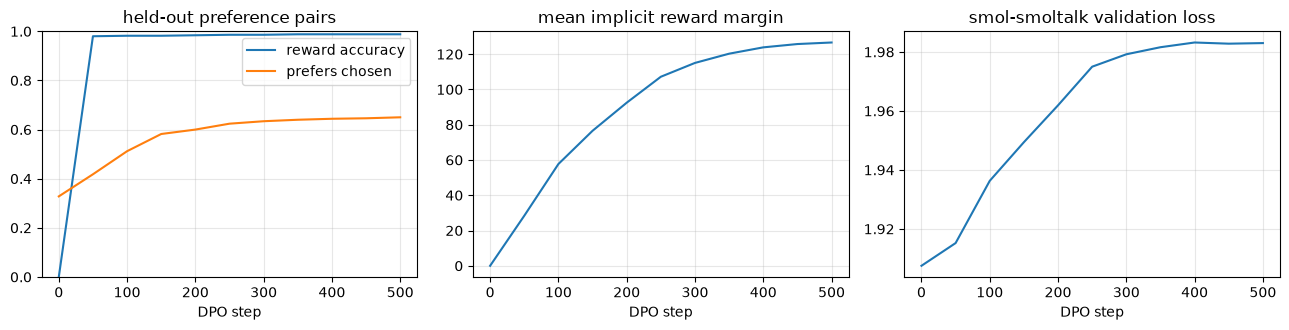

{
 "steps": 500,
 "pairs_train": 4000,
 "pairs_eval": 500,
 "beta": 0.1,
 "reward_acc_after": 0.988,
 "reward_margin_after": 126.6039,
 "prefers_chosen_before": 0.328,
 "prefers_chosen_after": 0.65,
 "chat_val_loss_before": 1.9075,
 "chat_val_loss_after": 1.983,
 "minutes": 25.3,
 "data": {
  "dataset": "Intel/orca_dpo_pairs",
  "rows_read": 12859,
  "kept": 4500,
  "dropped_too_long_or_invalid": 3143,
  "train": 4000,
  "eval": 500,
  "mean_prompt_tokens": 126.0,
  "mean_chosen_tokens": 115.3,
  "mean_rejected_tokens": 192.6
 }
}


In [9]:
import pandas as pd, matplotlib.pyplot as plt, json
log = pd.read_csv('/content/drive/MyDrive/nova_base/runs/moe_dpo/log.csv')
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(log.step, log.reward_acc, label='reward accuracy'); ax[0].plot(log.step, log.prefers_chosen, label='prefers chosen')
ax[0].set_ylim(0, 1); ax[0].legend(); ax[0].set_title('held-out preference pairs')
ax[1].plot(log.step, log.reward_margin); ax[1].set_title('mean implicit reward margin')
ax[2].plot(log.step, log.chat_val_loss); ax[2].set_title('smol-smoltalk validation loss')
for a in ax: a.set_xlabel('DPO step'); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig('/content/drive/MyDrive/nova_base/results/dpo_curves.png', dpi=150); plt.show()
print(json.dumps(json.load(open('/content/drive/MyDrive/nova_base/runs/moe_dpo/DONE.json')), indent=1))

## Answers before and after DPO
Same questions, sampling settings and seed for both models. After DPO the answers are much shorter: the first is correct and concise, but the others are truncated, repetitive or off-topic. Because the preferred answers in the training pairs are on average 40% shorter than the rejected ones, the model has learned brevity more than quality, the length exploitation known from DPO. A smaller learning rate, a larger β or length-controlled pairs would be the next step.

In [10]:
import torch
from chat import Chat, load_chat_model
qs = ['What is the capital of France?', 'Give me three tips for studying for exams.',
      'Why is exercise good for health?', 'Explain photosynthesis in simple words.']
for name in ['moe_sft/ckpt_best.pt', 'moe_dpo/ckpt_last.pt']:
    m, tok = load_chat_model('/content/drive/MyDrive/nova_base/runs/' + name, '/content/drive/MyDrive/nova_base/data')
    print('=' * 30, name.split('/')[0], '=' * 30)
    for q in qs:
        torch.manual_seed(0); bot = Chat(m, tok, temperature=0.3, top_k=10, repetition_penalty=1.2, max_new_tokens=100)
        print('You:   ', q); print('NovaLM:', bot.reply(q), '\n')

============================== moe_sft ==============================
You:    What is the capital of France?
NovaLM: The capital of France is Paris. It is located in the country's central region, approximately 2.5 million kilometers (3.6 billion kilometers) from the capital city of Paris. The capital of France is Paris, which is a major hub for economic and cultural activities.

The capital of France is Paris, which is a major hub for trade, education, and entertainment. The capital is Paris, which is famous for its historical landmarks like the Louvre Museum, the Louv 

You:    Give me three tips for studying for exams.
NovaLM: 1. **Dialogue**: A good starting point is to focus on the subject and the exam's purpose, rather than just the exam itself.
2. **Effective Practice**: This involves setting clear goals for each exam, taking into account any additional information or constraints that may be required.
3. **Explain the basics of the exam - The exam should have a clear understandin

## Routing change: pretraining → SFT → DPO
Share of probe tokens (64 windows × 512 tokens) whose pair of experts differs between stages, per MoE layer. DPO changes the experts of only 6-8% of tokens, against 26-30% for chat tuning, even though it changes the model's behaviour markedly.

In [11]:
import numpy as np, pandas as pd
from routing_analysis import load_model, get_probe_set, collect
probe = get_probe_set('/content/drive/MyDrive/nova_base/data', n_seq=64, T=512)
stages = {'pretrained': 'moe/ckpt_last.pt', 'sft': 'moe_sft/ckpt_best.pt', 'dpo': 'moe_dpo/ckpt_last.pt'}
R = {k: collect(load_model('/content/drive/MyDrive/nova_base/runs/' + v, 'cuda'), probe, 'cuda') for k, v in stages.items()}
rows = []
for a, b in [('pretrained', 'sft'), ('sft', 'dpo'), ('pretrained', 'dpo')]:
    for i in R['sft']['moe_layers']:
        x, y = np.sort(R[a][f'L{i}_top_idx'], -1), np.sort(R[b][f'L{i}_top_idx'], -1)
        rows.append({'from': a, 'to': b, 'layer': i, 'tokens_changed_%': round(100 * (x != y).any(-1).mean(), 1)})
flips = pd.DataFrame(rows); flips.to_csv('/content/drive/MyDrive/nova_base/results/dpo_routing_change.csv', index=False)
flips.pivot(index=['from', 'to'], columns='layer', values='tokens_changed_%')

layer             2     6     10
from       to                   
pretrained dpo  27.3  29.3  31.1
           sft  26.1  28.9  29.9
sft        dpo   6.2   5.8   8.3